# Laboratorio 8 — Embeddings

En este laboratorio se estudian representaciones distribucionales utilizando
un corpus de noticias en español y el texto de Don Quijote.

In [1]:
from pathlib import Path
from collections import Counter
import re

import numpy as np
import pandas as pd


# El notebook debe ejecutarse desde el directorio Lab8.
BASE_DIR = Path.cwd()

if BASE_DIR.name != "Lab8":
    raise RuntimeError(
        f"El notebook debe ejecutarse desde Lab8. Directorio actual: {BASE_DIR}"
    )

NEWS_PATH = BASE_DIR / "df_total.csv"
QUIJOTE_PATH = BASE_DIR / "don-quijote.txt"

for path in (NEWS_PATH, QUIJOTE_PATH):
    if not path.exists():
        raise FileNotFoundError(f"No se encontró el archivo: {path}")


# Carga robusta para detectar la codificación disponible.
def load_news_csv(path):
    encodings = ["utf-8-sig", "utf-8", "cp1252", "latin-1"]

    for encoding in encodings:
        try:
            dataframe = pd.read_csv(path, encoding=encoding)
            return dataframe, encoding
        except UnicodeDecodeError:
            continue

    raise UnicodeDecodeError(
        "No fue posible leer el CSV con las codificaciones probadas."
    )


news_df, news_encoding = load_news_csv(NEWS_PATH)

with open(QUIJOTE_PATH, "r", encoding="utf-8", errors="replace") as file:
    quijote_text = file.read()

print(f"Directorio de trabajo: {BASE_DIR}")
print(f"Codificación utilizada para noticias: {news_encoding}")
print(f"Noticias cargadas: {len(news_df):,}")
print(f"Columnas: {list(news_df.columns)}")
print(f"Caracteres en Don Quijote: {len(quijote_text):,}")

display(news_df.head(3))

required_columns = {"news", "Type"}
missing_columns = required_columns.difference(news_df.columns)

if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {missing_columns}")

print("\nMuestra de una noticia:")
print(news_df["news"].dropna().iloc[0][:500])

print("\nMuestra de Don Quijote:")
print(quijote_text[:500])

Directorio de trabajo: c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8
Codificación utilizada para noticias: utf-8-sig
Noticias cargadas: 1,217
Columnas: ['url', 'news', 'Type']
Caracteres en Don Quijote: 2,117,498


,url,news,Type
0,https://www.larepublica.co/redirect/post/3201905,Durante el foro La banca articulador empresari...,Otra
1,https://www.larepublica.co/redirect/post/3210288,El regulador de valores de China dijo el domin...,Regulaciones
2,https://www.larepublica.co/redirect/post/3240676,En una industria históricamente masculina como...,Alianzas



Muestra de una noticia:
Durante el foro La banca articulador empresarial para el desarrollo sostenible el director de sostenibilidad y clientes globales de BBVA en Colombia Andrés García aseguró que es importante entender que la sostenibilidad no la podemos asociar a mayores costos. Yo creo que el no tener un concepto de negocio sostenible puede tener un mayor impacto de lo que imaginamos.Para García el reto más importante es no cambiar prioridades ni que compitan entre sí necesariamente. En muchos de los casos se debe

Muestra de Don Quijote:
﻿The Project Gutenberg EBook of Don Quijote, by Miguel de Cervantes Saavedra

This eBook is for the use of anyone anywhere at no cost and with
almost no restrictions whatsoever.  You may copy it, give it away or
re-use it under the terms of the Project Gutenberg License included
with this eBook or online at www.gutenberg.net


Title: Don Quijote

Author: Miguel de Cervantes Saavedra

Posting Date: April 27, 2010 [EBook #2000]
Release Date: Decem

In [2]:
TOKEN_PATTERN = re.compile(
    r"[A-Za-zÁÉÍÓÚÜÑáéíóúüñ]+(?:[-'][A-Za-zÁÉÍÓÚÜÑáéíóúüñ]+)?"
)


def split_sentences(text):
    """Segmentación básica conservando palabras con tildes."""
    text = re.sub(r"\s+", " ", str(text)).strip()
    if not text:
        return []
    return [
        sentence.strip()
        for sentence in re.split(r"(?<=[.!?])\s+", text)
        if sentence.strip()
    ]


def tokenize(text):
    """Tokenización alfabética, preservando tildes y ñ."""
    return TOKEN_PATTERN.findall(str(text).lower())


news_documents = news_df["news"].fillna("").astype(str).tolist()

news_sentences = [
    sentence
    for document in news_documents
    for sentence in split_sentences(document)
]

news_tokens = [
    token
    for document in news_documents
    for token in tokenize(document)
]

quijote_sentences = split_sentences(quijote_text)
quijote_tokens = tokenize(quijote_text)

summary = pd.DataFrame(
    [
        {
            "corpus": "Noticias",
            "documentos": len(news_documents),
            "oraciones": len(news_sentences),
            "tokens": len(news_tokens),
            "tipos": len(set(news_tokens)),
        },
        {
            "corpus": "Don Quijote",
            "documentos": 1,
            "oraciones": len(quijote_sentences),
            "tokens": len(quijote_tokens),
            "tipos": len(set(quijote_tokens)),
        },
    ]
)

display(summary)

print("Ejemplo de tokens de noticias:", news_tokens[:30])
print("Ejemplo de tokens de Don Quijote:", quijote_tokens[:30])

accented_tokens = [
    token for token in news_tokens
    if any(character in "áéíóúüñ" for character in token)
]

print(f"Tokens con tildes o ñ en noticias: {len(accented_tokens):,}")
print("Ejemplos:", accented_tokens[:20])

,corpus,documentos,oraciones,tokens,tipos
0,Noticias,1217,15605,622771,27805
1,Don Quijote,1,9577,384261,23593


Ejemplo de tokens de noticias: ['durante', 'el', 'foro', 'la', 'banca', 'articulador', 'empresarial', 'para', 'el', 'desarrollo', 'sostenible', 'el', 'director', 'de', 'sostenibilidad', 'y', 'clientes', 'globales', 'de', 'bbva', 'en', 'colombia', 'andrés', 'garcía', 'aseguró', 'que', 'es', 'importante', 'entender', 'que']
Ejemplo de tokens de Don Quijote: ['the', 'project', 'gutenberg', 'ebook', 'of', 'don', 'quijote', 'by', 'miguel', 'de', 'cervantes', 'saavedra', 'this', 'ebook', 'is', 'for', 'the', 'use', 'of', 'anyone', 'anywhere', 'at', 'no', 'cost', 'and', 'with', 'almost', 'no', 'restrictions', 'whatsoever']
Tokens con tildes o ñ en noticias: 71,356
Ejemplos: ['andrés', 'garcía', 'aseguró', 'garcía', 'más', 'sí', 'ambición', 'más', 'agregó', 'argumentó', 'acá', 'físico', 'además', 'físicos', 'transición', 'climático', 'inclusión', 'están', 'ahí', 'dejó']


In [4]:
def clean_gutenberg_text_precisely(text):
    text_upper = text.upper()

    start_marker = "*** START OF THIS PROJECT GUTENBERG EBOOK DON QUIJOTE ***"
    start_marker_index = text_upper.find(start_marker)

    if start_marker_index == -1:
        raise ValueError("No se encontró el marcador inicial de Gutenberg.")

    content_start = start_marker_index + len(start_marker)

    # El contenido útil comienza con el título español.
    title_index = text.find("El ingenioso hidalgo", content_start)
    if title_index != -1:
        content_start = title_index

    end_marker = "End of Project Gutenberg's Don Quijote"
    end_marker_index = text.find(end_marker, content_start)

    if end_marker_index == -1:
        raise ValueError("No se encontró el marcador final de Gutenberg.")

    return text[content_start:end_marker_index].strip()


def normalize_sentence_spacing_conservative(text):
    """
    Corrige casos como 'imaginamos.Para' sin separar abreviaturas
    como 'S.A.' o iniciales en mayúscula.
    """
    text = re.sub(r"\s+", " ", str(text)).strip()

    return re.sub(
        r"(?<=[a-záéíóúüñ])([.!?])(?=[A-ZÁÉÍÓÚÜÑ¿¡])",
        r"\1 ",
        text
    )


quijote_clean = clean_gutenberg_text_precisely(quijote_text)

news_documents_clean = [
    normalize_sentence_spacing_conservative(document)
    for document in news_df["news"].fillna("").astype(str)
]

quijote_clean = normalize_sentence_spacing_conservative(quijote_clean)

news_sentences_clean = [
    sentence
    for document in news_documents_clean
    for sentence in split_sentences(document)
]

news_tokens_clean = [
    token
    for document in news_documents_clean
    for token in tokenize(document)
]

quijote_sentences_clean = split_sentences(quijote_clean)
quijote_tokens_clean = tokenize(quijote_clean)

summary_clean = pd.DataFrame(
    [
        {
            "corpus": "Noticias",
            "documentos": len(news_documents_clean),
            "oraciones": len(news_sentences_clean),
            "tokens": len(news_tokens_clean),
            "tipos": len(set(news_tokens_clean)),
        },
        {
            "corpus": "Don Quijote",
            "documentos": 1,
            "oraciones": len(quijote_sentences_clean),
            "tokens": len(quijote_tokens_clean),
            "tipos": len(set(quijote_tokens_clean)),
        },
    ]
)

display(summary_clean)

print("Inicio limpio:")
print(quijote_clean[:300])

print("\nFinal limpio:")
print(quijote_clean[-300:])

print("\n¿Quedó texto de Gutenberg?")
print("project gutenberg" in quijote_clean.lower())
print("produced by" in quijote_clean.lower())
print("end of project gutenberg" in quijote_clean.lower())

print("\nTokens iniciales de Don Quijote:")
print(quijote_tokens_clean[:30])

,corpus,documentos,oraciones,tokens,tipos
0,Noticias,1217,21144,622771,27805
1,Don Quijote,1,9451,381223,22936


Inicio limpio:
El ingenioso hidalgo don Quijote de la Mancha TASA Yo, Juan Gallo de Andrada, escribano de Cámara del Rey nuestro señor, de los que residen en su Consejo, certifico y doy fe que, habiendo visto por los señores dél un libro intitulado El ingenioso hidalgo de la Mancha, compuesto por Miguel de Cervant

Final limpio:
ruto de sus escritos enteramente, como deseaba, pues no ha sido otro mi deseo que poner en aborrecimiento de los hombres las fingidas y disparatadas historias de los libros de caballerías, que, por las de mi verdadero don Quijote, van ya tropezando, y han de caer del todo, sin duda alguna. Vale. Fin

¿Quedó texto de Gutenberg?
False
False
False

Tokens iniciales de Don Quijote:
['el', 'ingenioso', 'hidalgo', 'don', 'quijote', 'de', 'la', 'mancha', 'tasa', 'yo', 'juan', 'gallo', 'de', 'andrada', 'escribano', 'de', 'cámara', 'del', 'rey', 'nuestro', 'señor', 'de', 'los', 'que', 'residen', 'en', 'su', 'consejo', 'certifico', 'y']


In [5]:
from collections import Counter


news_token_counts = Counter(news_tokens_clean)
quijote_token_counts = Counter(quijote_tokens_clean)


def min_count_coverage(tokens, corpus_name):
    counts = Counter(tokens)
    total_tokens = len(tokens)

    rows = []

    for min_count in (1, 2, 5):
        retained_tokens = sum(
            frequency
            for frequency in counts.values()
            if frequency >= min_count
        )

        retained_types = sum(
            1
            for frequency in counts.values()
            if frequency >= min_count
        )

        rows.append(
            {
                "corpus": corpus_name,
                "min_count": min_count,
                "tipos_totales": len(counts),
                "tipos_conservados": retained_types,
                "tokens_totales": total_tokens,
                "tokens_conservados": retained_tokens,
                "cobertura_tokens": retained_tokens / total_tokens,
                "porcentaje_cobertura": 100 * retained_tokens / total_tokens,
            }
        )

    return pd.DataFrame(rows)


coverage_table = pd.concat(
    [
        min_count_coverage(news_tokens_clean, "Noticias"),
        min_count_coverage(quijote_tokens_clean, "Don Quijote"),
    ],
    ignore_index=True,
)

display(
    coverage_table.style.format(
        {
            "cobertura_tokens": "{:.4f}",
            "porcentaje_cobertura": "{:.2f}%",
        }
    )
)

,corpus,min_count,tipos_totales,tipos_conservados,tokens_totales,tokens_conservados,cobertura_tokens,porcentaje_cobertura
0,Noticias,1,27805,27805,622771,622771,1.0000,100.00%
1,Noticias,2,27805,16191,622771,611157,0.9814,98.14%
2,Noticias,5,27805,8541,622771,590767,0.9486,94.86%
3,Don Quijote,1,22936,22936,381223,381223,1.0000,100.00%
4,Don Quijote,2,22936,11760,381223,370047,0.9707,97.07%
5,Don Quijote,5,22936,5301,381223,353109,0.9263,92.63%


In [6]:
def skipgram_pairs_from_sentence(tokens, window_size):
    """
    Genera pares (palabra_centro, palabra_contexto) dentro de una oración.
    No cruza los límites de la oración.
    """
    pairs = []

    for center_index, center_word in enumerate(tokens):
        start = max(0, center_index - window_size)
        end = min(len(tokens), center_index + window_size + 1)

        for context_index in range(start, end):
            if context_index != center_index:
                pairs.append(
                    (center_word, tokens[context_index])
                )

    return pairs


def count_skipgram_pairs(sentences, window_size):
    """
    Cuenta pares sin almacenar toda la lista en memoria.
    """
    total_pairs = 0

    for sentence in sentences:
        sentence_tokens = tokenize(sentence)
        total_pairs += len(
            skipgram_pairs_from_sentence(sentence_tokens, window_size)
        )

    return total_pairs


def collect_skipgram_pairs(sentences, window_size, max_pairs=None):
    """
    Recolecta pares para inspección o experimentos pequeños.
    """
    pairs = []

    for sentence in sentences:
        sentence_tokens = tokenize(sentence)
        sentence_pairs = skipgram_pairs_from_sentence(
            sentence_tokens,
            window_size,
        )

        if max_pairs is None:
            pairs.extend(sentence_pairs)
        else:
            remaining = max_pairs - len(pairs)
            pairs.extend(sentence_pairs[:remaining])

            if len(pairs) >= max_pairs:
                break

    return pairs


news_pairs_window_2 = collect_skipgram_pairs(
    news_sentences_clean,
    window_size=2,
    max_pairs=20,
)

quijote_pairs_window_2 = collect_skipgram_pairs(
    quijote_sentences_clean,
    window_size=2,
    max_pairs=20,
)

pair_counts = pd.DataFrame(
    [
        {
            "corpus": "Noticias",
            "ventana": 2,
            "pares_totales": count_skipgram_pairs(
                news_sentences_clean,
                window_size=2,
            ),
        },
        {
            "corpus": "Noticias",
            "ventana": 5,
            "pares_totales": count_skipgram_pairs(
                news_sentences_clean,
                window_size=5,
            ),
        },
        {
            "corpus": "Don Quijote",
            "ventana": 2,
            "pares_totales": count_skipgram_pairs(
                quijote_sentences_clean,
                window_size=2,
            ),
        },
        {
            "corpus": "Don Quijote",
            "ventana": 5,
            "pares_totales": count_skipgram_pairs(
                quijote_sentences_clean,
                window_size=5,
            ),
        },
    ]
)

display(pair_counts)

print("Primeros pares skip-gram de Noticias:")
print(news_pairs_window_2)

print("\nPrimeros pares skip-gram de Don Quijote:")
print(quijote_pairs_window_2)

,corpus,ventana,pares_totales
0,Noticias,2,2364536
1,Noticias,5,5597052
2,Don Quijote,2,1468288
3,Don Quijote,5,3534180


Primeros pares skip-gram de Noticias:
[('durante', 'el'), ('durante', 'foro'), ('el', 'durante'), ('el', 'foro'), ('el', 'la'), ('foro', 'durante'), ('foro', 'el'), ('foro', 'la'), ('foro', 'banca'), ('la', 'el'), ('la', 'foro'), ('la', 'banca'), ('la', 'articulador'), ('banca', 'foro'), ('banca', 'la'), ('banca', 'articulador'), ('banca', 'empresarial'), ('articulador', 'la'), ('articulador', 'banca'), ('articulador', 'empresarial')]

Primeros pares skip-gram de Don Quijote:
[('el', 'ingenioso'), ('el', 'hidalgo'), ('ingenioso', 'el'), ('ingenioso', 'hidalgo'), ('ingenioso', 'don'), ('hidalgo', 'el'), ('hidalgo', 'ingenioso'), ('hidalgo', 'don'), ('hidalgo', 'quijote'), ('don', 'ingenioso'), ('don', 'hidalgo'), ('don', 'quijote'), ('don', 'de'), ('quijote', 'hidalgo'), ('quijote', 'don'), ('quijote', 'de'), ('quijote', 'la'), ('de', 'don'), ('de', 'quijote'), ('de', 'la')]


In [7]:
# Tokenización por oración para evitar cruces entre oraciones.
news_tokenized_sentences = [
    tokenize(sentence)
    for sentence in news_sentences_clean
]

news_word_counts = Counter(news_tokens_clean)
cooc_vocab = [
    word
    for word, _ in news_word_counts.most_common(2_000)
]

word_to_index = {
    word: index
    for index, word in enumerate(cooc_vocab)
}

cooc_matrix = np.zeros(
    (len(cooc_vocab), len(cooc_vocab)),
    dtype=np.int32,
)


def build_cooccurrence_matrix(tokenized_sentences, vocabulary, window_size=2):
    """
    Construye una matriz simétrica de coocurrencias dentro de cada oración.
    """
    index = {
        word: position
        for position, word in enumerate(vocabulary)
    }

    matrix = np.zeros(
        (len(vocabulary), len(vocabulary)),
        dtype=np.int32,
    )

    for sentence_tokens in tokenized_sentences:
        for center_position, center_word in enumerate(sentence_tokens):
            if center_word not in index:
                continue

            center_index = index[center_word]
            start = max(0, center_position - window_size)
            end = min(
                len(sentence_tokens),
                center_position + window_size + 1,
            )

            for context_position in range(start, end):
                if context_position == center_position:
                    continue

                context_word = sentence_tokens[context_position]

                if context_word in index:
                    context_index = index[context_word]
                    matrix[center_index, context_index] += 1

    return matrix


cooc_matrix = build_cooccurrence_matrix(
    news_tokenized_sentences,
    cooc_vocab,
    window_size=2,
)

zero_percentage = 100 * np.mean(cooc_matrix == 0)

print(f"Forma de la matriz: {cooc_matrix.shape}")
print(f"Valores totales: {cooc_matrix.size:,}")
print(f"Porcentaje de ceros: {zero_percentage:.2f}%")
print(f"Coocurrencias no nulas: {np.count_nonzero(cooc_matrix):,}")

Forma de la matriz: (2000, 2000)
Valores totales: 4,000,000
Porcentaje de ceros: 93.85%
Coocurrencias no nulas: 245,995


In [8]:
def cosine_similarity_numpy(vector_a, vector_b):
    norm_a = np.linalg.norm(vector_a)
    norm_b = np.linalg.norm(vector_b)

    if norm_a == 0 or norm_b == 0:
        return np.nan

    return float(np.dot(vector_a, vector_b) / (norm_a * norm_b))


def cooccurrence_similarity(word_a, word_b):
    if word_a not in word_to_index or word_b not in word_to_index:
        return {
            "palabra_a": word_a,
            "palabra_b": word_b,
            "similitud": np.nan,
            "estado": "fuera_del_vocabulario",
        }

    index_a = word_to_index[word_a]
    index_b = word_to_index[word_b]

    similarity = cosine_similarity_numpy(
        cooc_matrix[index_a],
        cooc_matrix[index_b],
    )

    return {
        "palabra_a": word_a,
        "palabra_b": word_b,
        "similitud": similarity,
        "estado": "calculada",
    }


comparison_pairs = [
    ("empresa", "negocio"),
    ("empresa", "gobierno"),
    ("gobierno", "estado"),
    ("banco", "empresa"),
    ("mercado", "economía"),
]

similarity_table = pd.DataFrame(
    [
        cooccurrence_similarity(word_a, word_b)
        for word_a, word_b in comparison_pairs
    ]
)

display(
    similarity_table.style.format(
        {"similitud": "{:.4f}"}
    )
)


def top_contexts(word, matrix, vocabulary, top_n=10):
    if word not in vocabulary:
        return pd.DataFrame(
            columns=["palabra", "coocurrencias"]
        )

    word_index = vocabulary.index(word)
    row = matrix[word_index].copy()
    row[word_index] = 0

    best_indices = np.argsort(row)[::-1][:top_n]

    return pd.DataFrame(
        {
            "palabra": [vocabulary[index] for index in best_indices],
            "coocurrencias": row[best_indices],
        }
    )


print("Contextos principales de 'empresa':")
display(top_contexts("empresa", cooc_matrix, cooc_vocab))

print("Contextos principales de 'gobierno':")
display(top_contexts("gobierno", cooc_matrix, cooc_vocab))

,palabra_a,palabra_b,similitud,estado
0,empresa,negocio,0.6183,calculada
1,empresa,gobierno,0.3781,calculada
2,gobierno,estado,0.7821,calculada
3,banco,empresa,0.4345,calculada
4,mercado,economía,0.4111,calculada


Contextos principales de 'empresa':


,palabra,coocurrencias
0,la,205
1,de,153
2,una,65
3,en,49
4,que,47
5,y,39
6,a,33
7,con,28
8,para,19
9,como,17


Contextos principales de 'gobierno':


,palabra,coocurrencias
0,el,218
1,del,108
2,de,84
3,que,65
4,y,56
5,nacional,36
6,en,31
7,por,24
8,para,24
9,al,24


In [9]:
def build_ppmi_matrix(cooccurrence_matrix):
    """
    Calcula PPMI a partir de una matriz de coocurrencia.

    PPMI(i,j) = max(PMI(i,j), 0)
    PMI(i,j) = log2(P(i,j) / (P(i)P(j)))
    """
    counts = cooccurrence_matrix.astype(np.float64)

    total_count = counts.sum()
    row_marginals = counts.sum(axis=1)
    column_marginals = counts.sum(axis=0)

    expected_denominator = np.outer(
        row_marginals,
        column_marginals,
    )

    ppmi = np.zeros_like(counts, dtype=np.float32)
    positive_entries = counts > 0

    with np.errstate(divide="ignore", invalid="ignore"):
        pmi_values = np.log2(
            (counts[positive_entries] * total_count)
            / expected_denominator[positive_entries]
        )

    ppmi[positive_entries] = np.maximum(pmi_values, 0)

    return ppmi


ppmi_matrix = build_ppmi_matrix(cooc_matrix)

print(f"Forma de la matriz PPMI: {ppmi_matrix.shape}")
print(f"Valores positivos: {np.count_nonzero(ppmi_matrix):,}")
print(f"Valores iguales a cero: {np.sum(ppmi_matrix == 0):,}")
print(f"Valor máximo de PPMI: {ppmi_matrix.max():.4f}")
print(f"Valor promedio de PPMI: {ppmi_matrix.mean():.4f}")

Forma de la matriz PPMI: (2000, 2000)
Valores positivos: 196,740
Valores iguales a cero: 3,803,260
Valor máximo de PPMI: 12.3493
Valor promedio de PPMI: 0.1368


In [10]:
def ppmi_similarity(word_a, word_b):
    if word_a not in word_to_index or word_b not in word_to_index:
        return {
            "palabra_a": word_a,
            "palabra_b": word_b,
            "similitud_ppmi": np.nan,
            "estado": "fuera_del_vocabulario",
        }

    index_a = word_to_index[word_a]
    index_b = word_to_index[word_b]

    similarity = cosine_similarity_numpy(
        ppmi_matrix[index_a],
        ppmi_matrix[index_b],
    )

    return {
        "palabra_a": word_a,
        "palabra_b": word_b,
        "similitud_ppmi": similarity,
        "estado": "calculada",
    }


ppmi_similarity_table = pd.DataFrame(
    [
        ppmi_similarity(word_a, word_b)
        for word_a, word_b in comparison_pairs
    ]
)

display(
    ppmi_similarity_table.style.format(
        {"similitud_ppmi": "{:.4f}"}
    )
)

print("Contextos PPMI principales de 'empresa':")
display(top_contexts("empresa", ppmi_matrix, cooc_vocab))

print("Contextos PPMI principales de 'gobierno':")
display(top_contexts("gobierno", ppmi_matrix, cooc_vocab))

,palabra_a,palabra_b,similitud_ppmi,estado
0,empresa,negocio,0.0591,calculada
1,empresa,gobierno,0.0838,calculada
2,gobierno,estado,0.1552,calculada
3,banco,empresa,0.1041,calculada
4,mercado,economía,0.1151,calculada


Contextos PPMI principales de 'empresa':


,palabra,coocurrencias
0,telecomunicaciones,5.436696
1,líder,5.146820
2,llega,5.070743
3,especializada,5.021658
4,cualquier,4.833612
5,estadounidense,4.671559
6,colombiana,4.564075
7,asegurar,4.553020
8,criterios,4.446891
9,española,4.240668


Contextos PPMI principales de 'gobierno':


,palabra,coocurrencias
0,corporativo,7.212930
1,federal,5.819156
2,sánchez,5.417932
3,nacional,5.288206
4,funcionarios,5.192219
5,iván,5.188906
6,estará,4.825234
7,petro,4.802273
8,mexicano,4.657883
9,llamado,4.564773


In [12]:
from pathlib import Path

from sklearn.decomposition import TruncatedSVD
from gensim.models import KeyedVectors


RANDOM_SEED = 42
SVD_DIMENSIONS = 100

svd = TruncatedSVD(
    n_components=SVD_DIMENSIONS,
    random_state=RANDOM_SEED,
)

svd_embeddings = svd.fit_transform(ppmi_matrix)

print(f"Forma de los embeddings SVD: {svd_embeddings.shape}")
print(
    "Varianza explicada acumulada: "
    f"{svd.explained_variance_ratio_.sum():.4f}"
)

models_dir = BASE_DIR / "models"
models_dir.mkdir(exist_ok=True)

svd_keyed_vectors = KeyedVectors(
    vector_size=SVD_DIMENSIONS
)

svd_keyed_vectors.add_vectors(
    cooc_vocab,
    svd_embeddings.astype(np.float32),
)

svd_path = models_dir / "svd_ppmi_news_100d.kv"
svd_keyed_vectors.save(str(svd_path))

print(f"Modelo guardado en: {svd_path}")
print(f"Palabras guardadas: {len(svd_keyed_vectors.key_to_index):,}")

Forma de los embeddings SVD: (2000, 100)
Varianza explicada acumulada: 0.2472
Modelo guardado en: c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8\models\svd_ppmi_news_100d.kv
Palabras guardadas: 2,000


In [13]:
def embedding_similarity(keyed_vectors, word_a, word_b):
    if (
        word_a not in keyed_vectors.key_to_index
        or word_b not in keyed_vectors.key_to_index
    ):
        return {
            "palabra_a": word_a,
            "palabra_b": word_b,
            "similitud": np.nan,
            "estado": "fuera_del_vocabulario",
        }

    return {
        "palabra_a": word_a,
        "palabra_b": word_b,
        "similitud": float(
            cosine_similarity_numpy(
                keyed_vectors[word_a],
                keyed_vectors[word_b],
            )
        ),
        "estado": "calculada",
    }


svd_similarity_table = pd.DataFrame(
    [
        embedding_similarity(svd_keyed_vectors, word_a, word_b)
        for word_a, word_b in comparison_pairs
    ]
)

display(
    svd_similarity_table.style.format(
        {"similitud": "{:.4f}"}
    )
)


def nearest_neighbors(keyed_vectors, word, top_n=10):
    if word not in keyed_vectors.key_to_index:
        return pd.DataFrame(
            columns=["palabra", "similitud"]
        )

    neighbors = keyed_vectors.most_similar(
        word,
        topn=top_n,
    )

    return pd.DataFrame(
        neighbors,
        columns=["palabra", "similitud"],
    )


print("Vecinos de 'empresa' en SVD:")
display(nearest_neighbors(svd_keyed_vectors, "empresa"))

print("Vecinos de 'gobierno' en SVD:")
display(nearest_neighbors(svd_keyed_vectors, "gobierno"))

print(f"Archivo existente: {svd_path.exists()}")

,palabra_a,palabra_b,similitud,estado
0,empresa,negocio,0.1716,calculada
1,empresa,gobierno,0.2517,calculada
2,gobierno,estado,0.4012,calculada
3,banco,empresa,0.3181,calculada
4,mercado,economía,0.4005,calculada


Vecinos de 'empresa' en SVD:


,palabra,similitud
0,compañía,0.641811
1,plataforma,0.634923
2,tecnología,0.619161
3,entidad,0.603092
4,asociación,0.568867
5,institución,0.568817
6,comunidad,0.568062
7,economía,0.559303
8,marca,0.558722
9,sociedad,0.549004


Vecinos de 'gobierno' en SVD:


,palabra,similitud
0,congreso,0.534702
1,banco,0.516047
2,consejo,0.497495
3,se,0.497239
4,dijo,0.492801
5,regulador,0.492305
6,comisión,0.491419
7,república,0.489730
8,cuando,0.482191
9,asociado,0.477415


Archivo existente: True


In [14]:
import time

from gensim.models import Word2Vec


# Corpus tokenizado que usará Word2Vec.
news_sentences_for_w2v = [
    tokenize(sentence)
    for sentence in news_sentences_clean
    if len(tokenize(sentence)) >= 2
]

control_words = [
    "empresa",
    "gobierno",
    "banco",
    "mercado",
    "economía",
    "negocio",
]

# Se verifica que las palabras de control puedan evaluarse.
control_presence = {
    word: sum(
        1
        for sentence in news_sentences_for_w2v
        if word in sentence
    )
    for word in control_words
}

display(
    pd.DataFrame(
        [
            {
                "palabra": word,
                "oraciones_con_palabra": count,
                "disponible": count > 0,
            }
            for word, count in control_presence.items()
        ]
    )
)

,palabra,oraciones_con_palabra,disponible
0,empresa,333,True
1,gobierno,362,True
2,banco,1028,True
3,mercado,725,True
4,economía,584,True
5,negocio,308,True


In [15]:
w2v_configs = {
    "base": {
        "vector_size": 100,
        "window": 5,
        "min_count": 2,
        "sg": 1,
        "negative": 5,
        "epochs": 10,
    },
    "window_2": {
        "vector_size": 100,
        "window": 2,
        "min_count": 2,
        "sg": 1,
        "negative": 5,
        "epochs": 10,
    },
    "vector_size_200": {
        "vector_size": 200,
        "window": 5,
        "min_count": 2,
        "sg": 1,
        "negative": 5,
        "epochs": 10,
    },
    "cbow": {
        "vector_size": 100,
        "window": 5,
        "min_count": 2,
        "sg": 0,
        "negative": 5,
        "epochs": 10,
    },
    "negative_10": {
        "vector_size": 100,
        "window": 5,
        "min_count": 2,
        "sg": 1,
        "negative": 10,
        "epochs": 10,
    },
}


def format_neighbors(model, word, top_n=5):
    if word not in model.wv.key_to_index:
        return "fuera_del_vocabulario"

    neighbors = model.wv.most_similar(word, topn=top_n)

    return "; ".join(
        f"{neighbor} ({similarity:.3f})"
        for neighbor, similarity in neighbors
    )


trained_models = {}
training_rows = []
neighbor_rows = []

models_dir.mkdir(exist_ok=True)

for model_name, config in w2v_configs.items():
    print(f"Entrenando: {model_name}")

    start_time = time.perf_counter()

    model = Word2Vec(
        sentences=news_sentences_for_w2v,
        vector_size=config["vector_size"],
        window=config["window"],
        min_count=config["min_count"],
        sg=config["sg"],
        negative=config["negative"],
        epochs=config["epochs"],
        workers=1,
        seed=RANDOM_SEED,
        sorted_vocab=1,
    )

    elapsed_seconds = time.perf_counter() - start_time

    trained_models[model_name] = model

    model_path = models_dir / f"word2vec_news_{model_name}.model"
    model.save(str(model_path))

    training_rows.append(
        {
            "modelo": model_name,
            "vector_size": config["vector_size"],
            "window": config["window"],
            "min_count": config["min_count"],
            "sg": config["sg"],
            "negative": config["negative"],
            "epochs": config["epochs"],
            "tiempo_segundos": elapsed_seconds,
            "vocabulario": len(model.wv),
            "ruta": str(model_path),
        }
    )

    for word in control_words:
        neighbor_rows.append(
            {
                "modelo": model_name,
                "palabra": word,
                "vecinos": format_neighbors(model, word),
            }
        )

    print(
        f"  Tiempo: {elapsed_seconds:.2f} s | "
        f"Vocabulario: {len(model.wv):,}"
    )

training_table = pd.DataFrame(training_rows)
neighbors_table = pd.DataFrame(neighbor_rows)

display(
    training_table.style.format(
        {"tiempo_segundos": "{:.2f}"}
    )
)

display(neighbors_table)

Entrenando: base
  Tiempo: 9.95 s | Vocabulario: 16,190
Entrenando: window_2
  Tiempo: 5.94 s | Vocabulario: 16,190
Entrenando: vector_size_200
  Tiempo: 16.90 s | Vocabulario: 16,190
Entrenando: cbow
  Tiempo: 4.21 s | Vocabulario: 16,190
Entrenando: negative_10
  Tiempo: 17.39 s | Vocabulario: 16,190


,modelo,vector_size,window,min_count,sg,negative,epochs,tiempo_segundos,vocabulario,ruta
0,base,100,5,2,1,5,10,9.95,16190,c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8\models\word2vec_news_base.model
1,window_2,100,2,2,1,5,10,5.94,16190,c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8\models\word2vec_news_window_2.model
2,vector_size_200,200,5,2,1,5,10,16.90,16190,c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8\models\word2vec_news_vector_size_200.model
3,cbow,100,5,2,0,5,10,4.21,16190,c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8\models\word2vec_news_cbow.model
4,negative_10,100,5,2,1,10,10,17.39,16190,c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8\models\word2vec_news_negative_10.model


,modelo,palabra,vecinos
0,base,empresa,startup (0.682); plataforma (0.659); compañía ...
1,base,gobierno,congreso (0.671); consejo (0.607); estímulo (0...
2,base,banco,central (0.717); popular (0.595); agrario (0.5...
3,base,mercado,sector (0.522); colombiano (0.496); accionario...
4,base,economía,mexicana (0.613); económica (0.578); incomplet...
5,base,negocio,ambiciosos (0.686); diferenciales (0.682); esc...
6,window_2,empresa,startup (0.718); compañía (0.700); ciudad (0.6...
7,window_2,gobierno,congreso (0.726); bce (0.669); federal (0.619)...
8,window_2,banco,central (0.623); popular (0.561); gnb (0.556);...
9,window_2,mercado,régimen (0.488); fútbol (0.485); representativ...


In [17]:
from gensim.models import FastText


quijote_sentences_for_w2v = [
    tokenize(sentence)
    for sentence in quijote_sentences_clean
    if len(tokenize(sentence)) >= 2
]

base_config = w2v_configs["base"]

# Word2Vec base sobre Don Quijote.
start_time = time.perf_counter()

quijote_w2v = Word2Vec(
    sentences=quijote_sentences_for_w2v,
    vector_size=base_config["vector_size"],
    window=base_config["window"],
    min_count=base_config["min_count"],
    sg=base_config["sg"],
    negative=base_config["negative"],
    epochs=base_config["epochs"],
    workers=1,
    seed=RANDOM_SEED,
    sorted_vocab=1,
)

quijote_elapsed = time.perf_counter() - start_time

quijote_w2v_path = models_dir / "word2vec_quijote_base.model"
quijote_w2v.save(str(quijote_w2v_path))

print(f"Tiempo Word2Vec Don Quijote: {quijote_elapsed:.2f} s")
print(f"Vocabulario Don Quijote: {len(quijote_w2v.wv):,}")
print(f"Modelo guardado en: {quijote_w2v_path}")


# FastText de gensim sobre noticias.
start_time = time.perf_counter()

news_fasttext = FastText(
    sentences=news_sentences_for_w2v,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    negative=5,
    epochs=10,
    min_n=3,
    max_n=6,
    workers=1,
    seed=RANDOM_SEED,
)

fasttext_elapsed = time.perf_counter() - start_time

fasttext_path = models_dir / "fasttext_news_base.model"
news_fasttext.save(str(fasttext_path))

print(f"\nTiempo FastText noticias: {fasttext_elapsed:.2f} s")
print(f"Vocabulario FastText: {len(news_fasttext.wv):,}")
print(f"Modelo guardado en: {fasttext_path}")

Tiempo Word2Vec Don Quijote: 6.17 s
Vocabulario Don Quijote: 11,756
Modelo guardado en: c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8\models\word2vec_quijote_base.model

Tiempo FastText noticias: 25.49 s
Vocabulario FastText: 16,190
Modelo guardado en: c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8\models\fasttext_news_base.model


In [18]:
candidate_shared_words = [
    "don",
    "hombre",
    "mujer",
    "casa",
    "tierra",
    "rey",
    "señor",
    "amor",
    "caballero",
    "mundo",
]

shared_words = [
    word
    for word in candidate_shared_words
    if (
        word in trained_models["base"].wv.key_to_index
        and word in quijote_w2v.wv.key_to_index
    )
]

print("Palabras candidatas presentes en ambos modelos:")
print(shared_words)

if len(shared_words) < 5:
    raise ValueError(
        "No se encontraron cinco palabras compartidas. "
        "Revisa los vocabularios antes de continuar."
    )

shared_words = shared_words[:5]

shared_neighbors = []

for word in shared_words:
    shared_neighbors.append(
        {
            "palabra": word,
            "vecinos_noticias": format_neighbors(
                trained_models["base"],
                word,
            ),
            "vecinos_quijote": format_neighbors(
                quijote_w2v,
                word,
            ),
        }
    )

shared_neighbors_table = pd.DataFrame(shared_neighbors)
display(shared_neighbors_table)

Palabras candidatas presentes en ambos modelos:
['don', 'hombre', 'mujer', 'casa', 'tierra', 'rey', 'señor', 'mundo']


,palabra,vecinos_noticias,vecinos_quijote
0,don,devolverle (0.955); iglesias (0.941); zora (0....,quijote (0.702); roque (0.635); ricote (0.614)...
1,hombre,fabricado (0.900); phi (0.880); defendiendo (0...,talle (0.744); viejo (0.737); honrado (0.716);...
2,mujer,inician (0.766); implementado (0.754); inclusi...,teresa (0.779); marido (0.762); hija (0.730); ...
3,casa,pasiva (0.662); ininterrumpidas (0.609); terra...,aldea (0.677); hacienda (0.635); compañía (0.6...
4,tierra,superficie (0.794); terrestre (0.787); extendi...,redondez (0.673); estrecheza (0.635); abismo (...


In [19]:
oov_words = {
    "error_tipografico": "empresaaa",
    "conjugacion_poco_comun": "gobernaríamos",
    "palabra_inventada": "zxqvembeddings",
}


def get_oov_comparison(word):
    in_word2vec = word in trained_models["base"].wv.key_to_index
    in_fasttext = word in news_fasttext.wv.key_to_index

    row = {
        "palabra": word,
        "word2vec_en_vocabulario": in_word2vec,
        "fasttext_en_vocabulario": in_fasttext,
        "word2vec_vector_disponible": False,
        "fasttext_vector_disponible": False,
        "fasttext_norma_vector": np.nan,
        "fasttext_vecinos": "",
    }

    if in_word2vec:
        row["word2vec_vector_disponible"] = True

    # FastText puede construir vectores a partir de subpalabras,
    # incluso si la palabra no aparece en su vocabulario explícito.
    try:
        fasttext_vector = news_fasttext.wv[word]
        row["fasttext_vector_disponible"] = True
        row["fasttext_norma_vector"] = np.linalg.norm(fasttext_vector)

        neighbors = news_fasttext.wv.most_similar(
            word,
            topn=5,
        )

        row["fasttext_vecinos"] = "; ".join(
            f"{neighbor} ({similarity:.3f})"
            for neighbor, similarity in neighbors
        )
    except KeyError:
        row["fasttext_vecinos"] = "no_disponible"

    return row


oov_table = pd.DataFrame(
    [
        get_oov_comparison(word)
        for word in oov_words.values()
    ]
)

display(oov_table)

,palabra,word2vec_en_vocabulario,fasttext_en_vocabulario,word2vec_vector_disponible,fasttext_vector_disponible,fasttext_norma_vector,fasttext_vecinos
0,empresaaa,False,False,False,True,3.419584,empresa (0.949); empresario (0.908); empresari...
1,gobernaríamos,False,False,False,True,2.312250,reclamos (0.881); reforzamos (0.873); imaginam...
2,zxqvembeddings,False,False,False,True,0.778321,bgt (0.912); iwgb (0.907); outlook (0.905); st...


In [20]:
available_models = {
    "SVD-PPMI noticias": svd_keyed_vectors,
    "Word2Vec noticias": trained_models["base"].wv,
    "Word2Vec Don Quijote": quijote_w2v.wv,
    "FastText noticias": news_fasttext.wv,
}


def model_contains_word(keyed_vectors, word):
    return word in keyed_vectors.key_to_index


def model_similarity(keyed_vectors, word_a, word_b):
    contains_a = model_contains_word(keyed_vectors, word_a)
    contains_b = model_contains_word(keyed_vectors, word_b)

    if not contains_a or not contains_b:
        missing = []

        if not contains_a:
            missing.append(word_a)

        if not contains_b:
            missing.append(word_b)

        return {
            "similitud": np.nan,
            "estado": "fuera_del_vocabulario",
            "faltantes": ", ".join(missing),
        }

    similarity = cosine_similarity_numpy(
        keyed_vectors[word_a],
        keyed_vectors[word_b],
    )

    return {
        "similitud": similarity,
        "estado": "calculada",
        "faltantes": "",
    }


def model_neighbors(keyed_vectors, word, top_n=5):
    """
    Usa únicamente palabras explícitamente presentes en el vocabulario.
    """
    if not model_contains_word(keyed_vectors, word):
        return {
            "vecinos": "fuera_del_vocabulario",
            "estado": "fuera_del_vocabulario",
        }

    neighbors = keyed_vectors.most_similar(
        word,
        topn=top_n,
    )

    return {
        "vecinos": "; ".join(
            f"{neighbor} ({similarity:.3f})"
            for neighbor, similarity in neighbors
        ),
        "estado": "calculado",
    }


# Comparación de cinco palabras de control por modelo.
neighbor_comparison_rows = []

for model_name, keyed_vectors in available_models.items():
    for word in control_words:
        result = model_neighbors(keyed_vectors, word)

        neighbor_comparison_rows.append(
            {
                "modelo": model_name,
                "palabra": word,
                "estado": result["estado"],
                "cinco_vecinos": result["vecinos"],
            }
        )

neighbor_comparison_table = pd.DataFrame(
    neighbor_comparison_rows
)

display(neighbor_comparison_table)

,modelo,palabra,estado,cinco_vecinos
0,SVD-PPMI noticias,empresa,calculado,compañía (0.642); plataforma (0.635); tecnolog...
1,SVD-PPMI noticias,gobierno,calculado,congreso (0.535); banco (0.516); consejo (0.49...
2,SVD-PPMI noticias,banco,calculado,grupo (0.625); central (0.616); bbva (0.615); ...
3,SVD-PPMI noticias,mercado,calculado,sector (0.703); sistema (0.665); mundo (0.603)...
4,SVD-PPMI noticias,economía,calculado,moneda (0.637); población (0.609); organizació...
5,SVD-PPMI noticias,negocio,calculado,sostenibilidad (0.504); financiamiento (0.485)...
6,Word2Vec noticias,empresa,calculado,startup (0.682); plataforma (0.659); compañía ...
7,Word2Vec noticias,gobierno,calculado,congreso (0.671); consejo (0.607); estímulo (0...
8,Word2Vec noticias,banco,calculado,central (0.717); popular (0.595); agrario (0.5...
9,Word2Vec noticias,mercado,calculado,sector (0.522); colombiano (0.496); accionario...


In [21]:
antonym_pairs = [
    ("bueno", "malo"),
    ("grande", "pequeño"),
    ("subir", "bajar"),
    ("ganar", "perder"),
]

antonym_rows = []

for model_name, keyed_vectors in available_models.items():
    for word_a, word_b in antonym_pairs:
        result = model_similarity(
            keyed_vectors,
            word_a,
            word_b,
        )

        antonym_rows.append(
            {
                "modelo": model_name,
                "palabra_a": word_a,
                "palabra_b": word_b,
                "similitud": result["similitud"],
                "estado": result["estado"],
                "faltantes": result["faltantes"],
            }
        )

antonym_table = pd.DataFrame(antonym_rows)

display(
    antonym_table.style.format(
        {"similitud": "{:.4f}"}
    )
)

,modelo,palabra_a,palabra_b,similitud,estado,faltantes
0,SVD-PPMI noticias,bueno,malo,nan,fuera_del_vocabulario,"bueno, malo"
1,SVD-PPMI noticias,grande,pequeño,nan,fuera_del_vocabulario,pequeño
2,SVD-PPMI noticias,subir,bajar,nan,fuera_del_vocabulario,bajar
3,SVD-PPMI noticias,ganar,perder,nan,fuera_del_vocabulario,"ganar, perder"
4,Word2Vec noticias,bueno,malo,0.7527,calculada,
5,Word2Vec noticias,grande,pequeño,0.4415,calculada,
6,Word2Vec noticias,subir,bajar,0.8040,calculada,
7,Word2Vec noticias,ganar,perder,0.7044,calculada,
8,Word2Vec Don Quijote,bueno,malo,0.8111,calculada,
9,Word2Vec Don Quijote,grande,pequeño,0.5027,calculada,


In [22]:
from scipy.stats import spearmanr


gold_standard = pd.DataFrame(
    [
        ("empresa", "compañía", 9),
        ("gobierno", "estado", 8),
        ("mercado", "economía", 8),
        ("banco", "dinero", 7),
        ("casa", "hogar", 9),
        ("trabajo", "empleo", 9),
        ("educación", "escuela", 8),
        ("presidente", "gobierno", 8),
        ("rey", "reina", 8),
        ("perro", "gato", 7),
        ("mar", "playa", 6),
        ("ciudad", "país", 6),
        ("salud", "enfermedad", 6),
        ("comprar", "vender", 6),
        ("amor", "odio", 4),
        ("mujer", "hombre", 3),
        ("ganar", "perder", 3),
        ("grande", "pequeño", 2),
        ("subir", "bajar", 3),
        ("empresa", "gobierno", 4),
    ],
    columns=["palabra_a", "palabra_b", "puntuacion_gold"],
)

display(gold_standard)

,palabra_a,palabra_b,puntuacion_gold
0,empresa,compañía,9
1,gobierno,estado,8
2,mercado,economía,8
3,banco,dinero,7
4,casa,hogar,9
5,trabajo,empleo,9
6,educación,escuela,8
7,presidente,gobierno,8
8,rey,reina,8
9,perro,gato,7


In [23]:
gold_results = []

for model_name, keyed_vectors in available_models.items():
    model_scores = []
    gold_scores = []
    covered_pairs = 0

    for _, row in gold_standard.iterrows():
        word_a = row["palabra_a"]
        word_b = row["palabra_b"]

        result = model_similarity(
            keyed_vectors,
            word_a,
            word_b,
        )

        if result["estado"] == "calculada":
            model_scores.append(result["similitud"])
            gold_scores.append(row["puntuacion_gold"])
            covered_pairs += 1

    coverage = covered_pairs / len(gold_standard)

    if len(model_scores) >= 2:
        spearman_value, spearman_pvalue = spearmanr(
            gold_scores,
            model_scores,
        )
    else:
        spearman_value = np.nan
        spearman_pvalue = np.nan

    gold_results.append(
        {
            "modelo": model_name,
            "pares_gold": len(gold_standard),
            "pares_con_cobertura": covered_pairs,
            "cobertura": coverage,
            "correlacion_spearman": spearman_value,
            "p_valor": spearman_pvalue,
        }
    )

gold_results_table = pd.DataFrame(gold_results)

display(
    gold_results_table.style.format(
        {
            "cobertura": "{:.2%}",
            "correlacion_spearman": "{:.4f}",
            "p_valor": "{:.4f}",
        }
    )
)

,modelo,pares_gold,pares_con_cobertura,cobertura,correlacion_spearman,p_valor
0,SVD-PPMI noticias,20,9,45.00%,0.2760,0.4722
1,Word2Vec noticias,20,18,90.00%,-0.1442,0.5680
2,Word2Vec Don Quijote,20,13,65.00%,-0.0418,0.8922
3,FastText noticias,20,18,90.00%,-0.2737,0.2717


In [24]:
gold_detail_rows = []

for model_name, keyed_vectors in available_models.items():
    for _, row in gold_standard.iterrows():
        result = model_similarity(
            keyed_vectors,
            row["palabra_a"],
            row["palabra_b"],
        )

        gold_detail_rows.append(
            {
                "modelo": model_name,
                "palabra_a": row["palabra_a"],
                "palabra_b": row["palabra_b"],
                "puntuacion_gold": row["puntuacion_gold"],
                "similitud_modelo": result["similitud"],
                "estado": result["estado"],
                "faltantes": result["faltantes"],
            }
        )

gold_detail_table = pd.DataFrame(gold_detail_rows)

display(gold_detail_table)

,modelo,palabra_a,palabra_b,puntuacion_gold,similitud_modelo,estado,faltantes
0,SVD-PPMI noticias,empresa,compañía,9,0.641811,calculada,
1,SVD-PPMI noticias,gobierno,estado,8,0.401219,calculada,
2,SVD-PPMI noticias,mercado,economía,8,0.400469,calculada,
3,SVD-PPMI noticias,banco,dinero,7,0.252185,calculada,
4,SVD-PPMI noticias,casa,hogar,9,0.352541,calculada,
...,...,...,...,...,...,...,...
75,FastText noticias,mujer,hombre,3,0.477708,calculada,
76,FastText noticias,ganar,perder,3,0.651490,calculada,
77,FastText noticias,grande,pequeño,2,0.568433,calculada,
78,FastText noticias,subir,bajar,3,0.786872,calculada,


In [25]:
analogy_tests = [
    # Género
    ("genero", "hombre", "mujer", "rey", "reina"),
    ("genero", "padre", "madre", "hijo", "hija"),
    ("genero", "señor", "señora", "actor", "actriz"),

    # Singular y plural
    ("plural", "empresa", "empresas", "banco", "bancos"),
    ("plural", "gobierno", "gobiernos", "mercado", "mercados"),
    ("plural", "ciudad", "ciudades", "país", "países"),

    # Antónimos
    ("antonimo", "grande", "pequeño", "alto", "bajo"),
    ("antonimo", "bueno", "malo", "ganar", "perder"),
    ("antonimo", "subir", "bajar", "entrar", "salir"),

    # País y ciudad
    ("geografia", "españa", "madrid", "francia", "parís"),
    ("geografia", "colombia", "bogotá", "españa", "madrid"),
    ("geografia", "méxico", "ciudad", "colombia", "bogotá"),

    # Relaciones familiares o sociales
    ("familia", "rey", "reina", "caballero", "dama"),
    ("familia", "padre", "hijo", "madre", "hija"),
    ("familia", "hermano", "hermana", "hombre", "mujer"),
]


def own_analogy(
    keyed_vectors,
    word_a,
    word_b,
    word_c,
    answer,
    top_n=5,
    exclude_query_words=True,
):
    query_words = [word_a, word_b, word_c]

    missing_query_words = [
        word
        for word in query_words
        if word not in keyed_vectors.key_to_index
    ]

    if missing_query_words:
        return {
            "estado": "consulta_fuera_del_vocabulario",
            "faltantes": ", ".join(missing_query_words),
            "top5_propio": "",
            "posicion_respuesta": np.nan,
            "correcta_top1": np.nan,
            "correcta_top5": np.nan,
        }

    if answer not in keyed_vectors.key_to_index:
        return {
            "estado": "respuesta_fuera_del_vocabulario",
            "faltantes": answer,
            "top5_propio": "",
            "posicion_respuesta": np.nan,
            "correcta_top1": np.nan,
            "correcta_top5": np.nan,
        }

    target_vector = (
        keyed_vectors[word_b]
        - keyed_vectors[word_a]
        + keyed_vectors[word_c]
    )

    target_norm = np.linalg.norm(target_vector)

    if target_norm == 0:
        return {
            "estado": "vector_resultante_nulo",
            "faltantes": "",
            "top5_propio": "",
            "posicion_respuesta": np.nan,
            "correcta_top1": 0,
            "correcta_top5": 0,
        }

    matrix = keyed_vectors.vectors
    matrix_norms = np.linalg.norm(matrix, axis=1)

    similarities = np.full(len(keyed_vectors.index_to_key), -np.inf)

    valid_norms = matrix_norms > 0
    similarities[valid_norms] = (
        matrix[valid_norms] @ target_vector
        / (matrix_norms[valid_norms] * target_norm)
    )

    if exclude_query_words:
        for word in query_words:
            index = keyed_vectors.key_to_index.get(word)
            if index is not None:
                similarities[index] = -np.inf

    ranking = np.argsort(similarities)[::-1]
    answer_index = keyed_vectors.key_to_index[answer]
    answer_positions = np.where(ranking == answer_index)[0]

    if len(answer_positions) == 0:
        answer_rank = np.nan
    else:
        answer_rank = int(answer_positions[0]) + 1

    top_indices = ranking[:top_n]
    top_words = [
        keyed_vectors.index_to_key[index]
        for index in top_indices
    ]

    top_scores = [
        similarities[index]
        for index in top_indices
    ]

    top5_text = "; ".join(
        f"{word} ({score:.3f})"
        for word, score in zip(top_words, top_scores)
    )

    return {
        "estado": "calculada",
        "faltantes": "",
        "top5_propio": top5_text,
        "posicion_respuesta": answer_rank,
        "correcta_top1": int(answer_rank == 1),
        "correcta_top5": int(answer_rank <= 5),
    }


def gensim_analogy(
    keyed_vectors,
    word_a,
    word_b,
    word_c,
    answer,
    top_n=5,
):
    query_words = [word_a, word_b, word_c]

    if any(
        word not in keyed_vectors.key_to_index
        for word in query_words
    ):
        return {
            "top5_gensim": "consulta_fuera_del_vocabulario",
            "posicion_gensim": np.nan,
        }

    if answer not in keyed_vectors.key_to_index:
        return {
            "top5_gensim": "respuesta_fuera_del_vocabulario",
            "posicion_gensim": np.nan,
        }

    try:
        neighbors = keyed_vectors.most_similar(
            positive=[word_b, word_c],
            negative=[word_a],
            topn=top_n,
        )

        top5_text = "; ".join(
            f"{word} ({score:.3f})"
            for word, score in neighbors
        )

        ranked_words = [word for word, _ in neighbors]

        if answer in ranked_words:
            answer_position = ranked_words.index(answer) + 1
        else:
            answer_position = np.nan

        return {
            "top5_gensim": top5_text,
            "posicion_gensim": answer_position,
        }

    except KeyError:
        return {
            "top5_gensim": "error_de_vocabulario",
            "posicion_gensim": np.nan,
        }


analogy_rows = []

for model_name, keyed_vectors in available_models.items():
    for analogy_type, word_a, word_b, word_c, answer in analogy_tests:
        own_result = own_analogy(
            keyed_vectors,
            word_a,
            word_b,
            word_c,
            answer,
            top_n=5,
            exclude_query_words=True,
        )

        gensim_result = gensim_analogy(
            keyed_vectors,
            word_a,
            word_b,
            word_c,
            answer,
            top_n=5,
        )

        analogy_rows.append(
            {
                "modelo": model_name,
                "tipo": analogy_type,
                "a": word_a,
                "b": word_b,
                "c": word_c,
                "respuesta_correcta": answer,
                "estado": own_result["estado"],
                "faltantes": own_result["faltantes"],
                "top5_propio": own_result["top5_propio"],
                "posicion_propia": own_result["posicion_respuesta"],
                "top1_propio": own_result["correcta_top1"],
                "top5_acierto_propio": own_result["correcta_top5"],
                "top5_gensim": gensim_result["top5_gensim"],
                "posicion_gensim": gensim_result["posicion_gensim"],
            }
        )

analogy_table = pd.DataFrame(analogy_rows)

display(analogy_table)

,modelo,tipo,a,b,c,respuesta_correcta,estado,faltantes,top5_propio,posicion_propia,top1_propio,top5_acierto_propio,top5_gensim,posicion_gensim
0,SVD-PPMI noticias,genero,hombre,mujer,rey,reina,consulta_fuera_del_vocabulario,"hombre, mujer, rey",,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
1,SVD-PPMI noticias,genero,padre,madre,hijo,hija,consulta_fuera_del_vocabulario,"padre, madre, hijo",,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
2,SVD-PPMI noticias,genero,señor,señora,actor,actriz,consulta_fuera_del_vocabulario,"señor, señora, actor",,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
3,SVD-PPMI noticias,plural,empresa,empresas,banco,bancos,calculada,,entidades (0.595); compañías (0.526); personas...,47.0,0.0,0.0,entidades (0.573); compañías (0.493); personas...,NaN
4,SVD-PPMI noticias,plural,gobierno,gobiernos,mercado,mercados,calculada,,segmentos (0.413); bancos (0.392); sector (0.3...,12.0,0.0,0.0,bancos (0.482); operadores (0.471); destinos (...,NaN
5,SVD-PPMI noticias,plural,ciudad,ciudades,país,países,calculada,,regiones (0.637); capitales (0.571); personas ...,140.0,0.0,0.0,regiones (0.574); empresas (0.530); categorías...,NaN
6,SVD-PPMI noticias,antonimo,grande,pequeño,alto,bajo,consulta_fuera_del_vocabulario,pequeño,,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
7,SVD-PPMI noticias,antonimo,bueno,malo,ganar,perder,consulta_fuera_del_vocabulario,"bueno, malo, ganar",,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
8,SVD-PPMI noticias,antonimo,subir,bajar,entrar,salir,consulta_fuera_del_vocabulario,bajar,,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
9,SVD-PPMI noticias,geografia,españa,madrid,francia,parís,respuesta_fuera_del_vocabulario,parís,,NaN,NaN,NaN,respuesta_fuera_del_vocabulario,NaN


In [26]:
analogy_summary = (
    analogy_table
    .query("estado == 'calculada'")
    .groupby(["modelo", "tipo"], as_index=False)
    .agg(
        pruebas=("respuesta_correcta", "count"),
        top1_propio=("top1_propio", "mean"),
        top5_propio=("top5_acierto_propio", "mean"),
        posicion_promedio=("posicion_propia", "mean"),
    )
)

display(
    analogy_summary.style.format(
        {
            "top1_propio": "{:.2%}",
            "top5_propio": "{:.2%}",
            "posicion_promedio": "{:.2f}",
        }
    )
)

,modelo,tipo,pruebas,top1_propio,top5_propio,posicion_promedio
0,FastText noticias,antonimo,3,0.00%,0.00%,1797.33
1,FastText noticias,familia,1,0.00%,100.00%,2.00
2,FastText noticias,genero,3,0.00%,33.33%,1463.33
3,FastText noticias,geografia,3,0.00%,33.33%,830.67
4,FastText noticias,plural,3,33.33%,66.67%,53.00
5,SVD-PPMI noticias,geografia,2,0.00%,50.00%,5.50
6,SVD-PPMI noticias,plural,3,0.00%,0.00%,66.33
7,Word2Vec Don Quijote,antonimo,3,0.00%,0.00%,2112.33
8,Word2Vec Don Quijote,familia,3,0.00%,0.00%,3549.33
9,Word2Vec Don Quijote,genero,2,0.00%,0.00%,166.50


In [27]:
analogy_summary = (
    analogy_table
    .query("estado == 'calculada'")
    .groupby(["modelo", "tipo"], as_index=False)
    .agg(
        pruebas=("respuesta_correcta", "count"),
        top1_propio=("top1_propio", "mean"),
        top5_propio=("top5_acierto_propio", "mean"),
        posicion_promedio=("posicion_propia", "mean"),
    )
)

display(
    analogy_summary.style.format(
        {
            "top1_propio": "{:.2%}",
            "top5_propio": "{:.2%}",
            "posicion_promedio": "{:.2f}",
        }
    )
)

,modelo,tipo,pruebas,top1_propio,top5_propio,posicion_promedio
0,FastText noticias,antonimo,3,0.00%,0.00%,1797.33
1,FastText noticias,familia,1,0.00%,100.00%,2.00
2,FastText noticias,genero,3,0.00%,33.33%,1463.33
3,FastText noticias,geografia,3,0.00%,33.33%,830.67
4,FastText noticias,plural,3,33.33%,66.67%,53.00
5,SVD-PPMI noticias,geografia,2,0.00%,50.00%,5.50
6,SVD-PPMI noticias,plural,3,0.00%,0.00%,66.33
7,Word2Vec Don Quijote,antonimo,3,0.00%,0.00%,2112.33
8,Word2Vec Don Quijote,familia,3,0.00%,0.00%,3549.33
9,Word2Vec Don Quijote,genero,2,0.00%,0.00%,166.50


In [28]:
analogy_global = (
    analogy_table
    .query("estado == 'calculada'")
    .groupby("modelo", as_index=False)
    .agg(
        pruebas=("respuesta_correcta", "count"),
        top1_propio=("top1_propio", "mean"),
        top5_propio=("top5_acierto_propio", "mean"),
        posicion_promedio=("posicion_propia", "mean"),
    )
)

display(
    analogy_global.style.format(
        {
            "top1_propio": "{:.2%}",
            "top5_propio": "{:.2%}",
            "posicion_promedio": "{:.2f}",
        }
    )
)

,modelo,pruebas,top1_propio,top5_propio,posicion_promedio
0,FastText noticias,13,7.69%,38.46%,956.54
1,SVD-PPMI noticias,5,0.00%,20.00%,42.00
2,Word2Vec Don Quijote,10,0.00%,0.00%,2182.10
3,Word2Vec noticias,13,0.00%,7.69%,3506.46


In [29]:
additional_analogies = [
    ("genero", "hombre", "mujer", "niño", "niña"),
    ("genero", "rey", "reina", "príncipe", "princesa"),
    ("plural", "empresa", "empresas", "gobierno", "gobiernos"),
    ("geografia", "españa", "madrid", "italia", "roma"),
    ("antonimo", "bueno", "malo", "fácil", "difícil"),
]

additional_rows = []

for model_name, keyed_vectors in available_models.items():
    for analogy_type, word_a, word_b, word_c, answer in additional_analogies:
        result = own_analogy(
            keyed_vectors,
            word_a,
            word_b,
            word_c,
            answer,
            top_n=5,
            exclude_query_words=False,
        )

        additional_rows.append(
            {
                "modelo": model_name,
                "tipo": analogy_type,
                "a": word_a,
                "b": word_b,
                "c": word_c,
                "respuesta_correcta": answer,
                "estado": result["estado"],
                "faltantes": result["faltantes"],
                "top5_propio": result["top5_propio"],
                "posicion": result["posicion_respuesta"],
                "top1": result["correcta_top1"],
                "top5": result["correcta_top5"],
            }
        )

additional_analogy_table = pd.DataFrame(additional_rows)

display(additional_analogy_table)

,modelo,tipo,a,b,c,respuesta_correcta,estado,faltantes,top5_propio,posicion,top1,top5
0,SVD-PPMI noticias,genero,hombre,mujer,niño,niña,consulta_fuera_del_vocabulario,"hombre, mujer, niño",,NaN,NaN,NaN
1,SVD-PPMI noticias,genero,rey,reina,príncipe,princesa,consulta_fuera_del_vocabulario,"rey, reina, príncipe",,NaN,NaN,NaN
2,SVD-PPMI noticias,plural,empresa,empresas,gobierno,gobiernos,calculada,,empresas (0.688); gobierno (0.637); acciones (...,10.0,0.0,0.0
3,SVD-PPMI noticias,geografia,españa,madrid,italia,roma,respuesta_fuera_del_vocabulario,roma,,NaN,NaN,NaN
4,SVD-PPMI noticias,antonimo,bueno,malo,fácil,difícil,consulta_fuera_del_vocabulario,"bueno, malo",,NaN,NaN,NaN
5,Word2Vec noticias,genero,hombre,mujer,niño,niña,calculada,,mujer (0.918); inician (0.710); redefinir (0.7...,4429.0,0.0,0.0
6,Word2Vec noticias,genero,rey,reina,príncipe,princesa,consulta_fuera_del_vocabulario,príncipe,,NaN,NaN,NaN
7,Word2Vec noticias,plural,empresa,empresas,gobierno,gobiernos,calculada,,empresas (0.711); gobierno (0.639); estímulo (...,15.0,0.0,0.0
8,Word2Vec noticias,geografia,españa,madrid,italia,roma,calculada,,madrid (0.605); medellín (0.565); roma (0.564)...,3.0,0.0,1.0
9,Word2Vec noticias,antonimo,bueno,malo,fácil,difícil,calculada,,fácil (0.901); segura (0.706); transparente (0...,4578.0,0.0,0.0


In [30]:
additional_summary = (
    additional_analogy_table
    .query("estado == 'calculada'")
    .groupby("modelo", as_index=False)
    .agg(
        pruebas=("respuesta_correcta", "count"),
        top1=("top1", "mean"),
        top5=("top5", "mean"),
        posicion_promedio=("posicion", "mean"),
    )
)

display(
    additional_summary.style.format(
        {
            "top1": "{:.2%}",
            "top5": "{:.2%}",
            "posicion_promedio": "{:.2f}",
        }
    )
)

,modelo,pruebas,top1,top5,posicion_promedio
0,FastText noticias,4,0.00%,25.00%,114.25
1,SVD-PPMI noticias,1,0.00%,0.00%,10.00
2,Word2Vec Don Quijote,5,0.00%,0.00%,2386.00
3,Word2Vec noticias,4,0.00%,25.00%,2256.25


In [31]:
w2v_variant_keyed_vectors = {
    model_name: model.wv
    for model_name, model in trained_models.items()
}

variant_evaluation_rows = []

for model_name, keyed_vectors in w2v_variant_keyed_vectors.items():
    # Evaluación del gold standard.
    gold_scores_model = []
    gold_scores_reference = []
    covered_gold_pairs = 0

    for _, row in gold_standard.iterrows():
        result = model_similarity(
            keyed_vectors,
            row["palabra_a"],
            row["palabra_b"],
        )

        if result["estado"] == "calculada":
            gold_scores_model.append(result["similitud"])
            gold_scores_reference.append(row["puntuacion_gold"])
            covered_gold_pairs += 1

    if len(gold_scores_model) >= 2:
        gold_spearman, gold_pvalue = spearmanr(
            gold_scores_reference,
            gold_scores_model,
        )
    else:
        gold_spearman = np.nan
        gold_pvalue = np.nan

    # Evaluación de las 15 analogías principales.
    analogy_top1 = []
    analogy_top5 = []
    analogy_positions = []
    covered_analogies = 0

    for analogy_type, word_a, word_b, word_c, answer in analogy_tests:
        result = own_analogy(
            keyed_vectors,
            word_a,
            word_b,
            word_c,
            answer,
            top_n=5,
            exclude_query_words=True,
        )

        if result["estado"] == "calculada":
            covered_analogies += 1
            analogy_top1.append(result["correcta_top1"])
            analogy_top5.append(result["correcta_top5"])
            analogy_positions.append(result["posicion_respuesta"])

    variant_evaluation_rows.append(
        {
            "modelo": model_name,
            "pares_gold_cubiertos": covered_gold_pairs,
            "cobertura_gold": covered_gold_pairs / len(gold_standard),
            "spearman_gold": gold_spearman,
            "p_valor_gold": gold_pvalue,
            "analogias_cubiertas": covered_analogies,
            "top1_analogias": (
                np.mean(analogy_top1)
                if analogy_top1
                else np.nan
            ),
            "top5_analogias": (
                np.mean(analogy_top5)
                if analogy_top5
                else np.nan
            ),
            "posicion_promedio": (
                np.mean(analogy_positions)
                if analogy_positions
                else np.nan
            ),
        }
    )

variant_evaluation_table = pd.DataFrame(
    variant_evaluation_rows
)

display(
    variant_evaluation_table.style.format(
        {
            "cobertura_gold": "{:.2%}",
            "spearman_gold": "{:.4f}",
            "p_valor_gold": "{:.4f}",
            "top1_analogias": "{:.2%}",
            "top5_analogias": "{:.2%}",
            "posicion_promedio": "{:.2f}",
        }
    )
)

,modelo,pares_gold_cubiertos,cobertura_gold,spearman_gold,p_valor_gold,analogias_cubiertas,top1_analogias,top5_analogias,posicion_promedio
0,base,18,90.00%,-0.1442,0.5680,13,0.00%,7.69%,3506.46
1,window_2,18,90.00%,-0.2506,0.3159,13,7.69%,7.69%,2431.77
2,vector_size_200,18,90.00%,-0.2158,0.3897,13,7.69%,15.38%,3073.00
3,cbow,18,90.00%,-0.0684,0.7873,13,7.69%,7.69%,2621.46
4,negative_10,18,90.00%,-0.2011,0.4236,13,0.00%,7.69%,3179.54


In [32]:
variant_neighbor_rows = []

for model_name, model in trained_models.items():
    for word in control_words:
        if word in model.wv.key_to_index:
            neighbors = model.wv.most_similar(word, topn=5)
            neighbors_text = "; ".join(
                f"{neighbor} ({score:.3f})"
                for neighbor, score in neighbors
            )
            status = "calculado"
        else:
            neighbors_text = "fuera_del_vocabulario"
            status = "fuera_del_vocabulario"

        variant_neighbor_rows.append(
            {
                "modelo": model_name,
                "palabra": word,
                "estado": status,
                "vecinos": neighbors_text,
            }
        )

variant_neighbors_table = pd.DataFrame(
    variant_neighbor_rows
)

display(variant_neighbors_table)

,modelo,palabra,estado,vecinos
0,base,empresa,calculado,startup (0.682); plataforma (0.659); compañía ...
1,base,gobierno,calculado,congreso (0.671); consejo (0.607); estímulo (0...
2,base,banco,calculado,central (0.717); popular (0.595); agrario (0.5...
3,base,mercado,calculado,sector (0.522); colombiano (0.496); accionario...
4,base,economía,calculado,mexicana (0.613); económica (0.578); incomplet...
5,base,negocio,calculado,ambiciosos (0.686); diferenciales (0.682); esc...
6,window_2,empresa,calculado,startup (0.718); compañía (0.700); ciudad (0.6...
7,window_2,gobierno,calculado,congreso (0.726); bce (0.669); federal (0.619)...
8,window_2,banco,calculado,central (0.623); popular (0.561); gnb (0.556);...
9,window_2,mercado,calculado,régimen (0.488); fútbol (0.485); representativ...


In [33]:
selection_table = variant_evaluation_table.sort_values(
    by=[
        "top5_analogias",
        "top1_analogias",
        "spearman_gold",
    ],
    ascending=False,
).reset_index(drop=True)

display(
    selection_table[
        [
            "modelo",
            "top5_analogias",
            "top1_analogias",
            "spearman_gold",
            "cobertura_gold",
        ]
    ].style.format(
        {
            "top5_analogias": "{:.2%}",
            "top1_analogias": "{:.2%}",
            "spearman_gold": "{:.4f}",
            "cobertura_gold": "{:.2%}",
        }
    )
)

selected_model_name = selection_table.loc[0, "modelo"]
selected_w2v_model = trained_models[selected_model_name]

selected_w2v_path = models_dir / "word2vec_news_selected.kv"

selected_w2v_model.wv.save(str(selected_w2v_path))

print(f"Modelo seleccionado: {selected_model_name}")
print(f"Modelo guardado en: {selected_w2v_path}")
print(f"Archivo existente: {selected_w2v_path.exists()}")
print(f"Dimensiones: {selected_w2v_model.wv.vector_size}")
print(f"Vocabulario: {len(selected_w2v_model.wv):,}")

,modelo,top5_analogias,top1_analogias,spearman_gold,cobertura_gold
0,vector_size_200,15.38%,7.69%,-0.2158,90.00%
1,cbow,7.69%,7.69%,-0.0684,90.00%
2,window_2,7.69%,7.69%,-0.2506,90.00%
3,base,7.69%,0.00%,-0.1442,90.00%
4,negative_10,7.69%,0.00%,-0.2011,90.00%


Modelo seleccionado: vector_size_200
Modelo guardado en: c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8\models\word2vec_news_selected.kv
Archivo existente: True
Dimensiones: 200
Vocabulario: 16,190


In [34]:
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


visualization_categories = {
    "economia": [
        "empresa", "negocio", "mercado", "economía", "banco",
        "dinero", "crédito", "deuda", "inversión", "precio",
        "costo", "venta", "compra", "empleo", "trabajo",
        "salario", "comercio", "industria", "sector",
        "financiamiento", "capital", "acciones", "bolsa",
        "moneda", "presupuesto",
    ],
    "politica": [
        "gobierno", "estado", "presidente", "congreso", "ministro",
        "alcalde", "partido", "elección", "política", "ley",
        "país", "nación", "autoridad", "funcionario", "regulador",
        "reforma", "candidato", "democracia", "tribunal", "justicia",
        "senado", "diputado", "gobernador", "mandatario", "voto",
    ],
    "sociedad": [
        "mujer", "hombre", "niño", "familia", "comunidad",
        "sociedad", "salud", "educación", "escuela", "universidad",
        "población", "ciudadano", "vivienda", "cultura", "seguridad",
        "problema", "ayuda", "servicio", "desarrollo", "pobreza",
        "igualdad", "inclusión", "derechos", "región", "pueblo",
    ],
    "tecnologia": [
        "tecnología", "plataforma", "internet", "digital", "datos",
        "sistema", "software", "aplicación", "red", "información",
        "telecomunicaciones", "celular", "móvil", "innovación",
        "programa", "online", "web", "ciberseguridad", "computadora",
        "usuario", "dispositivo", "nube", "inteligencia", "energía",
        "transporte",
    ],
    "geografia_ambiente": [
        "ciudad", "país", "mundo", "colombia", "méxico", "españa",
        "argentina", "bogotá", "madrid", "europa", "américa",
        "china", "estados", "unidos", "costa", "mar", "tierra",
        "clima", "climático", "ambiental", "agua", "río", "montaña",
        "aire", "naturaleza",
    ],
}


def get_visualization_words(category_dictionary, keyed_vectors):
    words = []
    categories = []

    for category, category_words in category_dictionary.items():
        for word in category_words:
            if (
                word in keyed_vectors.key_to_index
                and word not in words
            ):
                words.append(word)
                categories.append(category)

    return words, categories


selected_keyed_vectors = selected_w2v_model.wv

visualization_words_w2v, visualization_labels_w2v = (
    get_visualization_words(
        visualization_categories,
        selected_keyed_vectors,
    )
)

visualization_words_fasttext, visualization_labels_fasttext = (
    get_visualization_words(
        visualization_categories,
        news_fasttext.wv,
    )
)

common_visualization_words = sorted(
    set(visualization_words_w2v)
    & set(visualization_words_fasttext)
)

print(
    f"Palabras compartidas para visualización: "
    f"{len(common_visualization_words)}"
)

if len(common_visualization_words) < 30:
    raise ValueError(
        "Hay muy pocas palabras compartidas para una visualización útil."
    )

common_categories = {
    word: category
    for category, category_words in visualization_categories.items()
    for word in category_words
}

w2v_visualization_vectors = np.array(
    [
        selected_keyed_vectors[word]
        for word in common_visualization_words
    ]
)

fasttext_visualization_vectors = np.array(
    [
        news_fasttext.wv[word]
        for word in common_visualization_words
    ]
)

visualization_labels = [
    common_categories[word]
    for word in common_visualization_words
]

outputs_dir = BASE_DIR / "outputs"
outputs_dir.mkdir(exist_ok=True)

Palabras compartidas para visualización: 123


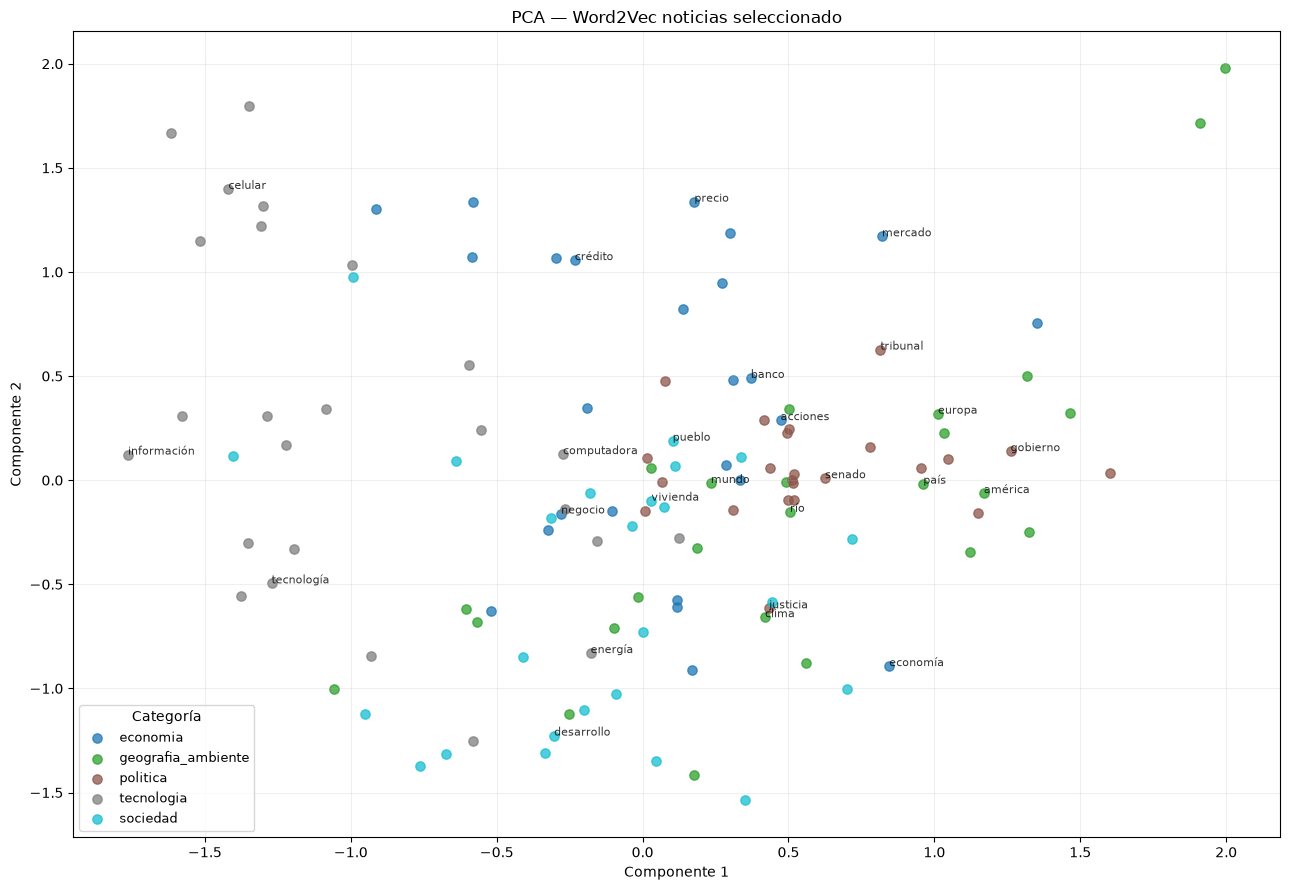

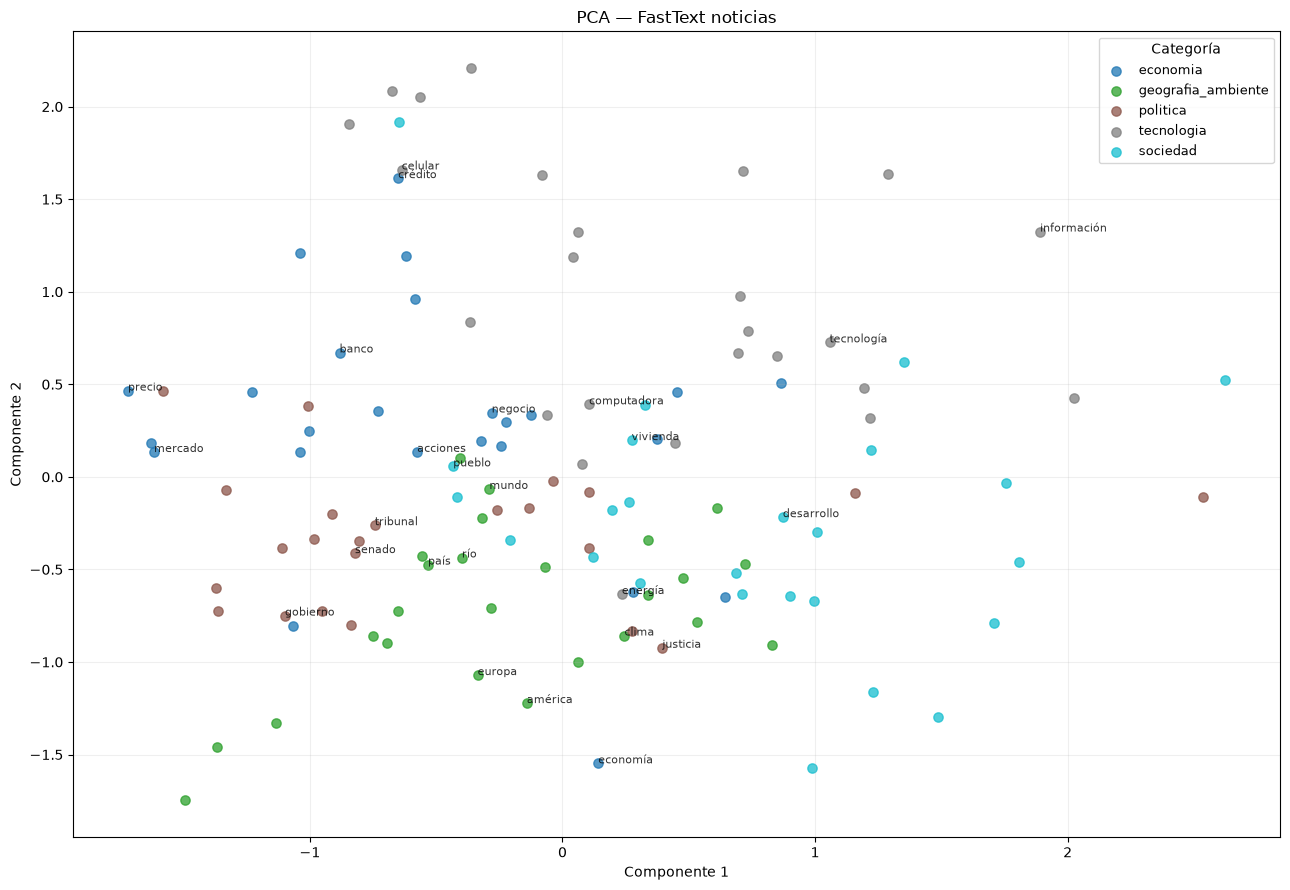

Varianza explicada PCA Word2Vec: 0.14266786
Varianza explicada PCA FastText: 0.14722085


In [37]:
def plot_projection(
    coordinates,
    words,
    categories,
    title,
    output_path,
    annotate_every=5,
):
    plt.figure(figsize=(13, 9))

    unique_categories = list(dict.fromkeys(categories))
    color_map = plt.get_cmap(
        "tab10",
        len(unique_categories),
    )

    for index, category in enumerate(unique_categories):
        selected_indices = [
            position
            for position, label in enumerate(categories)
            if label == category
        ]

        plt.scatter(
            coordinates[selected_indices, 0],
            coordinates[selected_indices, 1],
            s=45,
            alpha=0.75,
            label=category,
            color=color_map(index),
        )

    # Se etiquetan algunos puntos para evitar saturar la figura.
    for index in range(0, len(words), annotate_every):
        plt.annotate(
            words[index],
            (
                coordinates[index, 0],
                coordinates[index, 1],
            ),
            fontsize=8,
            alpha=0.8,
        )

    plt.title(title)
    plt.xlabel("Componente 1")
    plt.ylabel("Componente 2")
    plt.legend(title="Categoría", fontsize=9)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(output_path, dpi=180)
    plt.show()


# PCA separado para cada espacio.
pca_w2v = PCA(
    n_components=2,
    random_state=RANDOM_SEED,
)

pca_fasttext = PCA(
    n_components=2,
    random_state=RANDOM_SEED,
)

w2v_pca_coordinates = pca_w2v.fit_transform(
    w2v_visualization_vectors
)

fasttext_pca_coordinates = pca_fasttext.fit_transform(
    fasttext_visualization_vectors
)

plot_projection(
    w2v_pca_coordinates,
    common_visualization_words,
    visualization_labels,
    "PCA — Word2Vec noticias seleccionado",
    outputs_dir / "pca_word2vec_news_selected.png",
)

plot_projection(
    fasttext_pca_coordinates,
    common_visualization_words,
    visualization_labels,
    "PCA — FastText noticias",
    outputs_dir / "pca_fasttext_news.png",
)

print(
    "Varianza explicada PCA Word2Vec:",
    pca_w2v.explained_variance_ratio_.sum(),
)

print(
    "Varianza explicada PCA FastText:",
    pca_fasttext.explained_variance_ratio_.sum(),
)

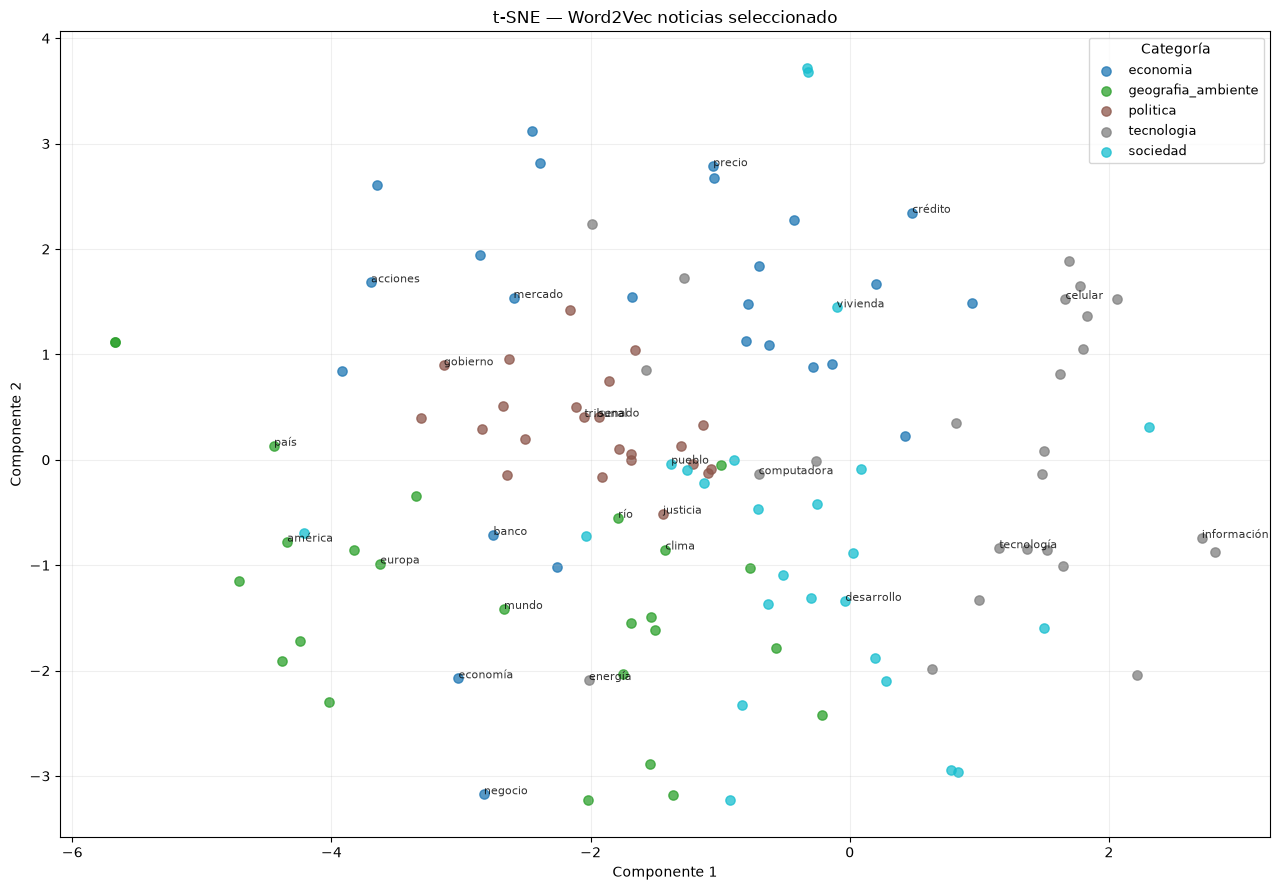

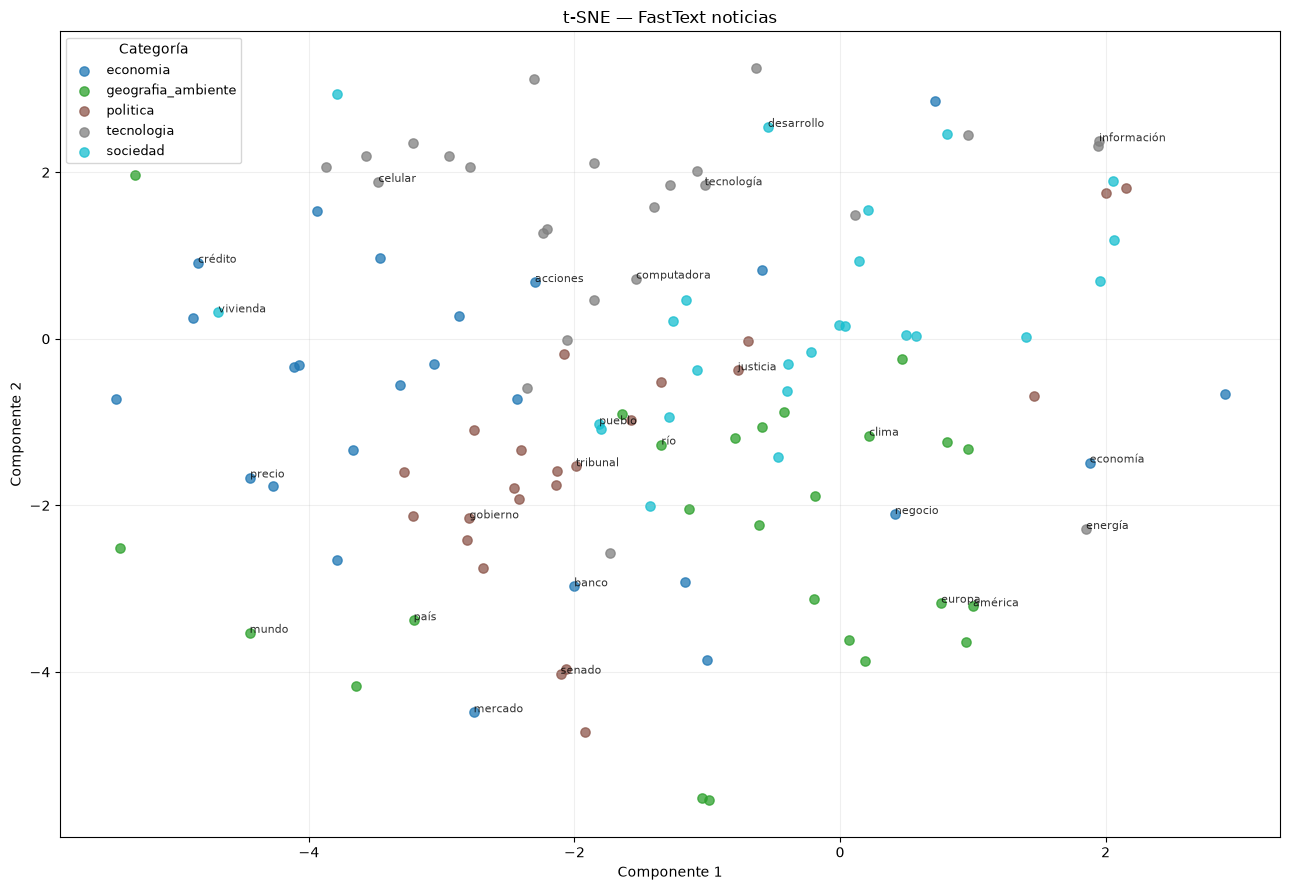

Perplexity utilizada: 30
Gráficas guardadas en: c:\Users\gianp\OneDrive\Escritorio\Semestre_8\NLP\Lab8\outputs


In [38]:
perplexity = min(
    30,
    max(5, (len(common_visualization_words) - 1) // 3),
)

tsne_w2v = TSNE(
    n_components=2,
    perplexity=perplexity,
    random_state=RANDOM_SEED,
    init="pca",
    learning_rate="auto",
    max_iter=1_000,
)

tsne_fasttext = TSNE(
    n_components=2,
    perplexity=perplexity,
    random_state=RANDOM_SEED,
    init="pca",
    learning_rate="auto",
    max_iter=1_000,
)

w2v_tsne_coordinates = tsne_w2v.fit_transform(
    w2v_visualization_vectors
)

fasttext_tsne_coordinates = tsne_fasttext.fit_transform(
    fasttext_visualization_vectors
)

plot_projection(
    w2v_tsne_coordinates,
    common_visualization_words,
    visualization_labels,
    "t-SNE — Word2Vec noticias seleccionado",
    outputs_dir / "tsne_word2vec_news_selected.png",
)

plot_projection(
    fasttext_tsne_coordinates,
    common_visualization_words,
    visualization_labels,
    "t-SNE — FastText noticias",
    outputs_dir / "tsne_fasttext_news.png",
)

print(f"Perplexity utilizada: {perplexity}")
print("Gráficas guardadas en:", outputs_dir)

In [39]:
fasttext_suc = KeyedVectors.load_word2vec_format(
    "data/embeddings-m-model.vec",
    binary=False,
    limit=200_000,
)

In [40]:
from gensim.models import KeyedVectors


fasttext_suc_path = BASE_DIR / "data" / "embeddings-m-model.vec"

if not fasttext_suc_path.exists():
    raise FileNotFoundError(f"No existe: {fasttext_suc_path}")

fasttext_suc = KeyedVectors.load_word2vec_format(
    str(fasttext_suc_path),
    binary=False,
    limit=200_000,
)

print("FastText SUC cargado correctamente")
print(f"Dimensiones: {fasttext_suc.vector_size}")
print(f"Vectores cargados: {len(fasttext_suc):,}")
print(f"Primeras palabras: {fasttext_suc.index_to_key[:10]}")

suc_control_table = pd.DataFrame(
    [
        {
            "palabra": word,
            "presente": word in fasttext_suc.key_to_index,
        }
        for word in control_words
    ]
)

display(suc_control_table)

suc_accented_words = [
    word
    for word in fasttext_suc.index_to_key[:10_000]
    if any(character in "áéíóúüñ" for character in word)
]

print("Ejemplos de palabras con tildes o ñ:")
print(suc_accented_words[:20])

FastText SUC cargado correctamente
Dimensiones: 100
Vectores cargados: 200,000
Primeras palabras: ['</s>', '.', 'de', ',', 'la', 'que', 'el', 'en', 'y', 'a']


,palabra,presente
0,empresa,True
1,gobierno,True
2,banco,True
3,mercado,True
4,economía,True
5,negocio,True


Ejemplos de palabras con tildes o ñ:
['qué', 'más', 'está', 'sí', 'aquí', 'así', 'también', 'él', 'sólo', 'años', 'cómo', 'tú', 'estás', 'sé', 'están', 'después', 'comisión', 'había', 'señor', 'día']


In [41]:
available_models_exact = {
    "SVD-PPMI noticias": svd_keyed_vectors,
    "Word2Vec noticias seleccionado": selected_w2v_model.wv,
    "Word2Vec Don Quijote": quijote_w2v.wv,
    "FastText SUC": fasttext_suc,
}


exact_neighbor_rows = []

for model_name, keyed_vectors in available_models_exact.items():
    for word in control_words:
        result = model_neighbors(
            keyed_vectors,
            word,
            top_n=5,
        )

        exact_neighbor_rows.append(
            {
                "modelo": model_name,
                "palabra": word,
                "estado": result["estado"],
                "cinco_vecinos": result["vecinos"],
            }
        )

exact_neighbors_table = pd.DataFrame(exact_neighbor_rows)

display(exact_neighbors_table)

,modelo,palabra,estado,cinco_vecinos
0,SVD-PPMI noticias,empresa,calculado,compañía (0.642); plataforma (0.635); tecnolog...
1,SVD-PPMI noticias,gobierno,calculado,congreso (0.535); banco (0.516); consejo (0.49...
2,SVD-PPMI noticias,banco,calculado,grupo (0.625); central (0.616); bbva (0.615); ...
3,SVD-PPMI noticias,mercado,calculado,sector (0.703); sistema (0.665); mundo (0.603)...
4,SVD-PPMI noticias,economía,calculado,moneda (0.637); población (0.609); organizació...
5,SVD-PPMI noticias,negocio,calculado,sostenibilidad (0.504); financiamiento (0.485)...
6,Word2Vec noticias seleccionado,empresa,calculado,startup (0.654); compañía (0.617); plataforma ...
7,Word2Vec noticias seleccionado,gobierno,calculado,congreso (0.650); plan (0.594); consejo (0.590...
8,Word2Vec noticias seleccionado,banco,calculado,central (0.702); república (0.589); popular (0...
9,Word2Vec noticias seleccionado,mercado,calculado,colombiano (0.430); sector (0.417); apetito (0...


In [42]:
exact_similarity_rows = []

for model_name, keyed_vectors in available_models_exact.items():
    for word_a, word_b in comparison_pairs:
        result = model_similarity(
            keyed_vectors,
            word_a,
            word_b,
        )

        exact_similarity_rows.append(
            {
                "modelo": model_name,
                "palabra_a": word_a,
                "palabra_b": word_b,
                "similitud": result["similitud"],
                "estado": result["estado"],
                "faltantes": result["faltantes"],
            }
        )

exact_similarity_table = pd.DataFrame(exact_similarity_rows)

display(
    exact_similarity_table.style.format(
        {"similitud": "{:.4f}"}
    )
)

,modelo,palabra_a,palabra_b,similitud,estado,faltantes
0,SVD-PPMI noticias,empresa,negocio,0.1716,calculada,
1,SVD-PPMI noticias,empresa,gobierno,0.2517,calculada,
2,SVD-PPMI noticias,gobierno,estado,0.4012,calculada,
3,SVD-PPMI noticias,banco,empresa,0.3181,calculada,
4,SVD-PPMI noticias,mercado,economía,0.4005,calculada,
5,Word2Vec noticias seleccionado,empresa,negocio,0.2846,calculada,
6,Word2Vec noticias seleccionado,empresa,gobierno,0.1180,calculada,
7,Word2Vec noticias seleccionado,gobierno,estado,0.4565,calculada,
8,Word2Vec noticias seleccionado,banco,empresa,0.2641,calculada,
9,Word2Vec noticias seleccionado,mercado,economía,0.2086,calculada,


In [43]:
exact_gold_rows = []

for model_name, keyed_vectors in available_models_exact.items():
    model_scores = []
    reference_scores = []
    covered_pairs = 0

    for _, row in gold_standard.iterrows():
        result = model_similarity(
            keyed_vectors,
            row["palabra_a"],
            row["palabra_b"],
        )

        if result["estado"] == "calculada":
            model_scores.append(result["similitud"])
            reference_scores.append(row["puntuacion_gold"])
            covered_pairs += 1

    if len(model_scores) >= 2:
        spearman_value, p_value = spearmanr(
            reference_scores,
            model_scores,
        )
    else:
        spearman_value = np.nan
        p_value = np.nan

    exact_gold_rows.append(
        {
            "modelo": model_name,
            "pares_gold": len(gold_standard),
            "pares_con_cobertura": covered_pairs,
            "cobertura": covered_pairs / len(gold_standard),
            "spearman": spearman_value,
            "p_valor": p_value,
        }
    )

exact_gold_table = pd.DataFrame(exact_gold_rows)

display(
    exact_gold_table.style.format(
        {
            "cobertura": "{:.2%}",
            "spearman": "{:.4f}",
            "p_valor": "{:.4f}",
        }
    )
)

,modelo,pares_gold,pares_con_cobertura,cobertura,spearman,p_valor
0,SVD-PPMI noticias,20,9,45.00%,0.2760,0.4722
1,Word2Vec noticias seleccionado,20,18,90.00%,-0.2158,0.3897
2,Word2Vec Don Quijote,20,13,65.00%,-0.0418,0.8922
3,FastText SUC,20,20,100.00%,0.0336,0.8882


In [44]:
exact_gold_detail_rows = []

for model_name, keyed_vectors in available_models_exact.items():
    for _, row in gold_standard.iterrows():
        result = model_similarity(
            keyed_vectors,
            row["palabra_a"],
            row["palabra_b"],
        )

        exact_gold_detail_rows.append(
            {
                "modelo": model_name,
                "palabra_a": row["palabra_a"],
                "palabra_b": row["palabra_b"],
                "puntuacion_gold": row["puntuacion_gold"],
                "similitud": result["similitud"],
                "estado": result["estado"],
                "faltantes": result["faltantes"],
            }
        )

exact_gold_detail = pd.DataFrame(exact_gold_detail_rows)

display(exact_gold_detail)

,modelo,palabra_a,palabra_b,puntuacion_gold,similitud,estado,faltantes
0,SVD-PPMI noticias,empresa,compañía,9,0.641811,calculada,
1,SVD-PPMI noticias,gobierno,estado,8,0.401219,calculada,
2,SVD-PPMI noticias,mercado,economía,8,0.400469,calculada,
3,SVD-PPMI noticias,banco,dinero,7,0.252185,calculada,
4,SVD-PPMI noticias,casa,hogar,9,0.352541,calculada,
...,...,...,...,...,...,...,...
75,FastText SUC,mujer,hombre,3,0.587402,calculada,
76,FastText SUC,ganar,perder,3,0.689466,calculada,
77,FastText SUC,grande,pequeño,2,0.710979,calculada,
78,FastText SUC,subir,bajar,3,0.937153,calculada,


In [45]:
exact_analogy_rows = []

for model_name, keyed_vectors in available_models_exact.items():
    for analogy_type, word_a, word_b, word_c, answer in analogy_tests:
        own_result = own_analogy(
            keyed_vectors,
            word_a,
            word_b,
            word_c,
            answer,
            top_n=5,
            exclude_query_words=True,
        )

        gensim_result = gensim_analogy(
            keyed_vectors,
            word_a,
            word_b,
            word_c,
            answer,
            top_n=5,
        )

        exact_analogy_rows.append(
            {
                "modelo": model_name,
                "tipo": analogy_type,
                "a": word_a,
                "b": word_b,
                "c": word_c,
                "respuesta_correcta": answer,
                "estado": own_result["estado"],
                "faltantes": own_result["faltantes"],
                "top5_propio": own_result["top5_propio"],
                "posicion_propia": own_result["posicion_respuesta"],
                "top1_propio": own_result["correcta_top1"],
                "top5_propio_acierto": own_result["correcta_top5"],
                "top5_gensim": gensim_result["top5_gensim"],
                "posicion_gensim": gensim_result["posicion_gensim"],
            }
        )

exact_analogy_table = pd.DataFrame(exact_analogy_rows)

display(exact_analogy_table)

,modelo,tipo,a,b,c,respuesta_correcta,estado,faltantes,top5_propio,posicion_propia,top1_propio,top5_propio_acierto,top5_gensim,posicion_gensim
0,SVD-PPMI noticias,genero,hombre,mujer,rey,reina,consulta_fuera_del_vocabulario,"hombre, mujer, rey",,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
1,SVD-PPMI noticias,genero,padre,madre,hijo,hija,consulta_fuera_del_vocabulario,"padre, madre, hijo",,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
2,SVD-PPMI noticias,genero,señor,señora,actor,actriz,consulta_fuera_del_vocabulario,"señor, señora, actor",,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
3,SVD-PPMI noticias,plural,empresa,empresas,banco,bancos,calculada,,entidades (0.595); compañías (0.526); personas...,47.0,0.0,0.0,entidades (0.573); compañías (0.493); personas...,NaN
4,SVD-PPMI noticias,plural,gobierno,gobiernos,mercado,mercados,calculada,,segmentos (0.413); bancos (0.392); sector (0.3...,12.0,0.0,0.0,bancos (0.482); operadores (0.471); destinos (...,NaN
5,SVD-PPMI noticias,plural,ciudad,ciudades,país,países,calculada,,regiones (0.637); capitales (0.571); personas ...,140.0,0.0,0.0,regiones (0.574); empresas (0.530); categorías...,NaN
6,SVD-PPMI noticias,antonimo,grande,pequeño,alto,bajo,consulta_fuera_del_vocabulario,pequeño,,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
7,SVD-PPMI noticias,antonimo,bueno,malo,ganar,perder,consulta_fuera_del_vocabulario,"bueno, malo, ganar",,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
8,SVD-PPMI noticias,antonimo,subir,bajar,entrar,salir,consulta_fuera_del_vocabulario,bajar,,NaN,NaN,NaN,consulta_fuera_del_vocabulario,NaN
9,SVD-PPMI noticias,geografia,españa,madrid,francia,parís,respuesta_fuera_del_vocabulario,parís,,NaN,NaN,NaN,respuesta_fuera_del_vocabulario,NaN


In [46]:
exact_analogy_summary = (
    exact_analogy_table
    .query("estado == 'calculada'")
    .groupby(["modelo", "tipo"], as_index=False)
    .agg(
        pruebas=("respuesta_correcta", "count"),
        top1=("top1_propio", "mean"),
        top5=("top5_propio_acierto", "mean"),
        posicion_promedio=("posicion_propia", "mean"),
    )
)

display(
    exact_analogy_summary.style.format(
        {
            "top1": "{:.2%}",
            "top5": "{:.2%}",
            "posicion_promedio": "{:.2f}",
        }
    )
)

exact_analogy_global = (
    exact_analogy_table
    .query("estado == 'calculada'")
    .groupby("modelo", as_index=False)
    .agg(
        pruebas=("respuesta_correcta", "count"),
        top1=("top1_propio", "mean"),
        top5=("top5_propio_acierto", "mean"),
        posicion_promedio=("posicion_propia", "mean"),
    )
)

display(
    exact_analogy_global.style.format(
        {
            "top1": "{:.2%}",
            "top5": "{:.2%}",
            "posicion_promedio": "{:.2f}",
        }
    )
)

,modelo,tipo,pruebas,top1,top5,posicion_promedio
0,FastText SUC,antonimo,3,33.33%,33.33%,121.33
1,FastText SUC,familia,3,66.67%,66.67%,2.67
2,FastText SUC,genero,3,100.00%,100.00%,1.00
3,FastText SUC,geografia,3,33.33%,66.67%,11.33
4,FastText SUC,plural,3,66.67%,100.00%,2.33
5,SVD-PPMI noticias,geografia,2,0.00%,50.00%,5.50
6,SVD-PPMI noticias,plural,3,0.00%,0.00%,66.33
7,Word2Vec Don Quijote,antonimo,3,0.00%,0.00%,2112.33
8,Word2Vec Don Quijote,familia,3,0.00%,0.00%,3549.33
9,Word2Vec Don Quijote,genero,2,0.00%,0.00%,166.50


,modelo,pruebas,top1,top5,posicion_promedio
0,FastText SUC,15,60.00%,73.33%,27.73
1,SVD-PPMI noticias,5,0.00%,20.00%,42.00
2,Word2Vec Don Quijote,10,0.00%,0.00%,2182.10
3,Word2Vec noticias seleccionado,13,7.69%,15.38%,3073.00


Palabras compartidas Word2Vec–SUC: 123


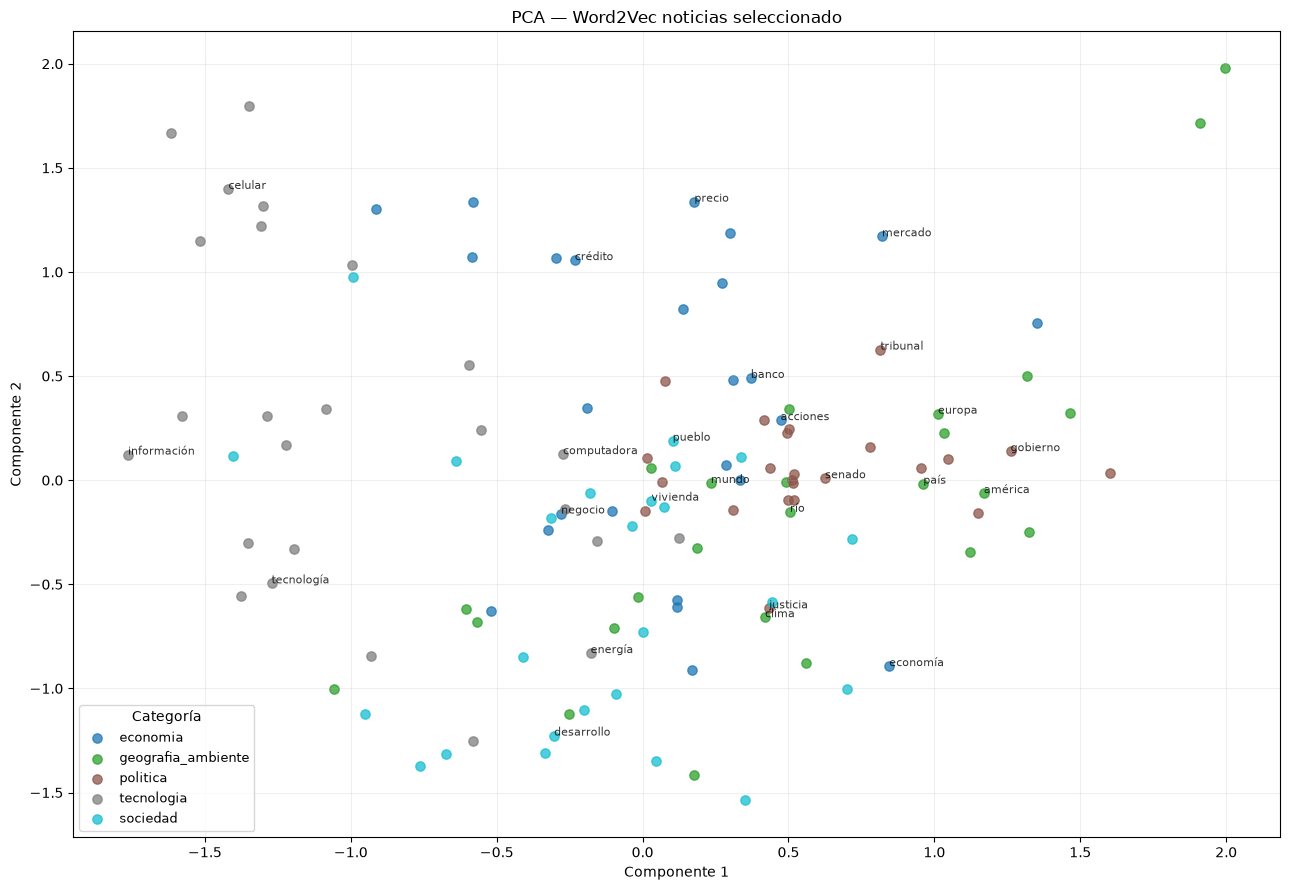

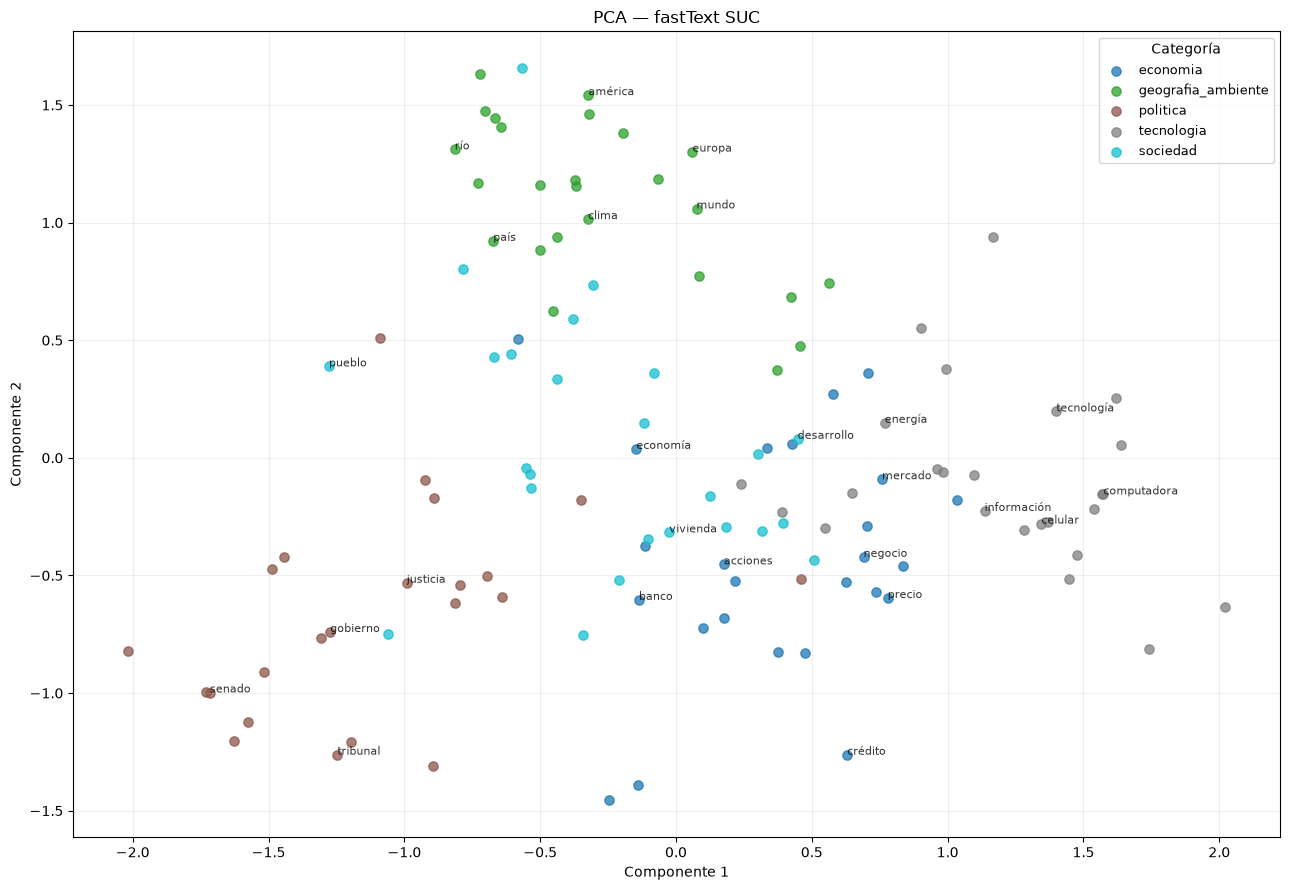

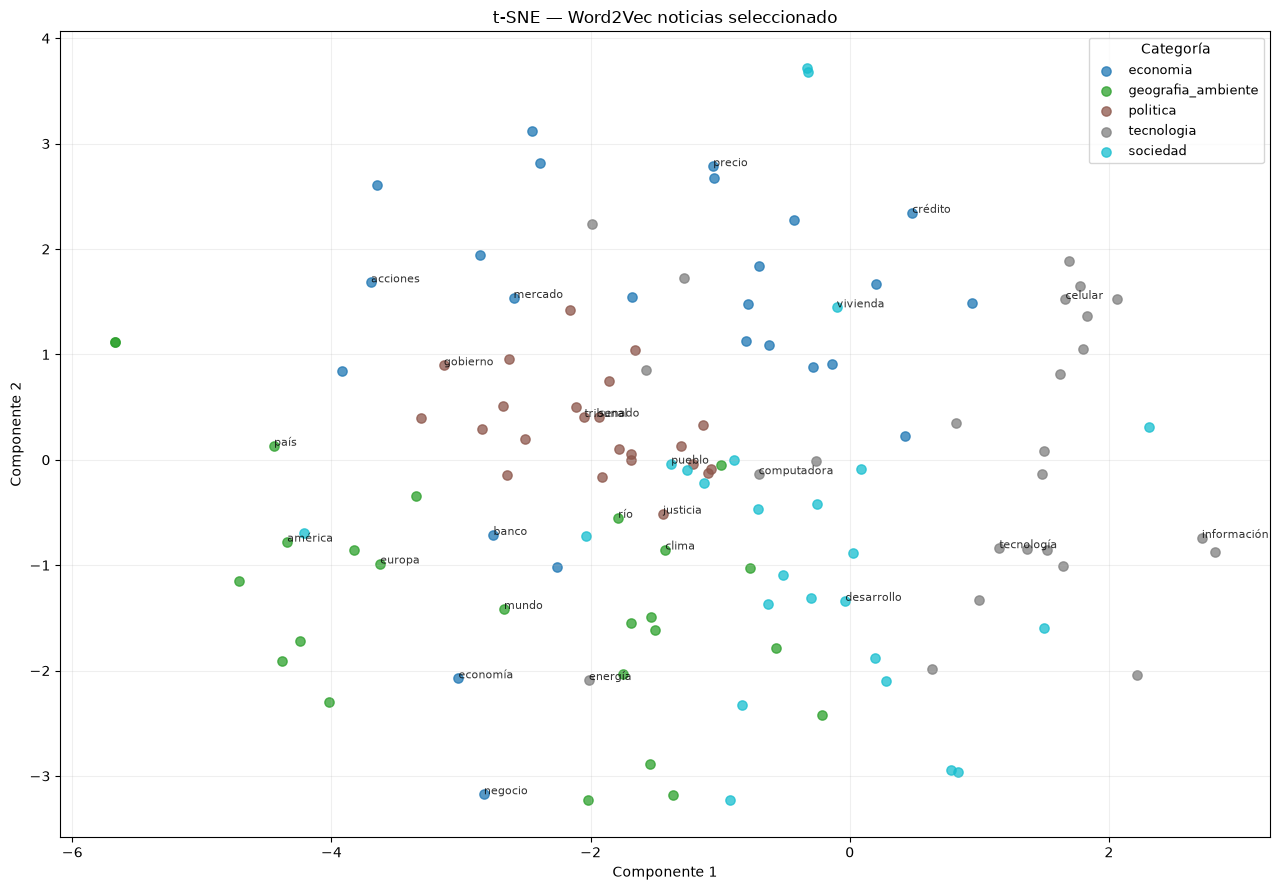

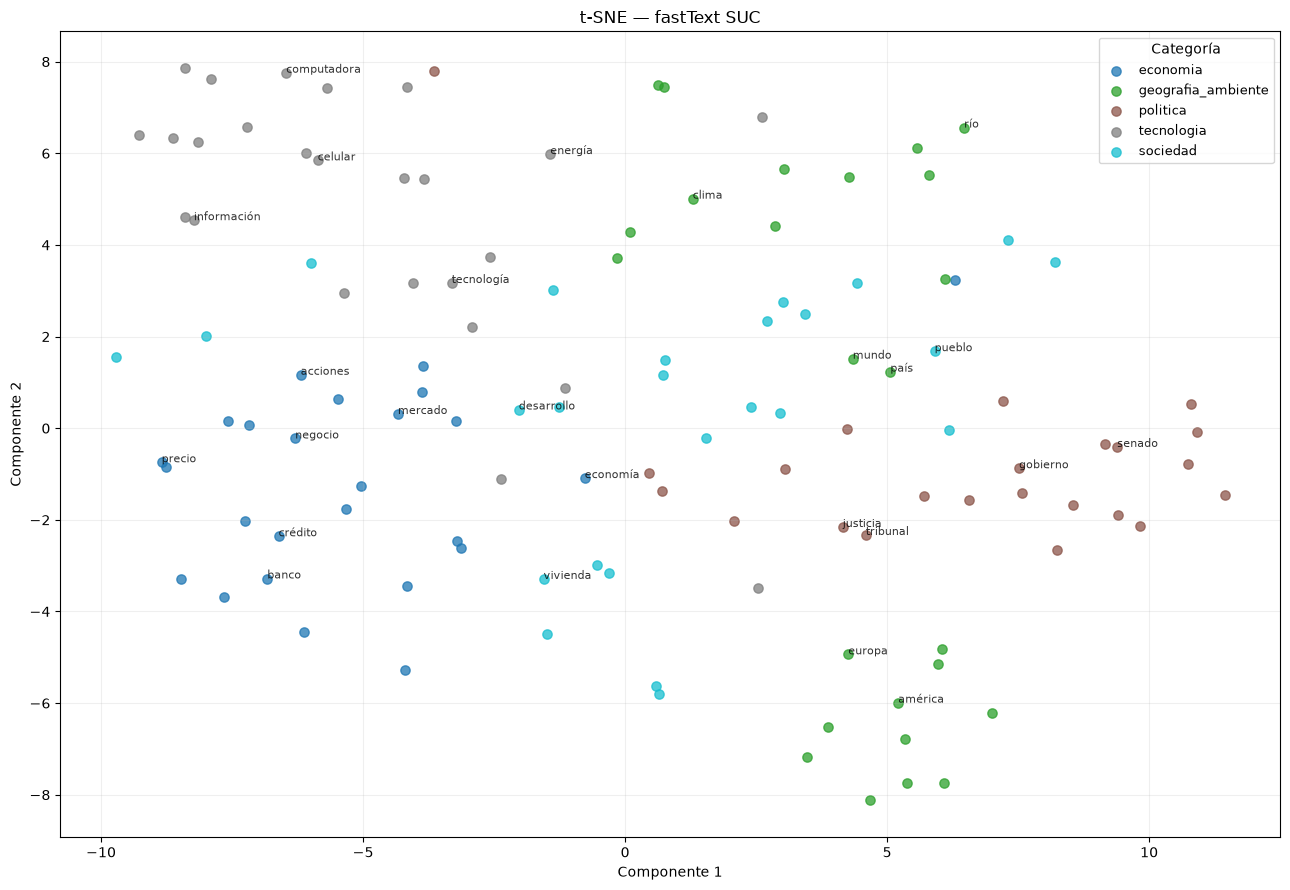

Varianza explicada PCA Word2Vec: 0.14266786
Varianza explicada PCA SUC: 0.1684353
Perplexity t-SNE: 30


In [51]:
# Comparación definitiva: Word2Vec propio contra fastText SUC.

selected_vectors = selected_w2v_model.wv

w2v_suc_words, w2v_suc_categories = get_visualization_words(
    visualization_categories,
    selected_vectors,
)

suc_words, suc_categories = get_visualization_words(
    visualization_categories,
    fasttext_suc,
)

common_suc_words = sorted(
    set(w2v_suc_words) & set(suc_words)
)

print(
    f"Palabras compartidas Word2Vec–SUC: "
    f"{len(common_suc_words)}"
)

if len(common_suc_words) < 30:
    raise ValueError(
        "Hay pocas palabras compartidas para una comparación estable."
    )

suc_category_map = {
    word: category
    for category, category_words in visualization_categories.items()
    for word in category_words
}

w2v_suc_labels = [
    suc_category_map[word]
    for word in common_suc_words
]

w2v_suc_vectors = np.array(
    [
        selected_vectors[word]
        for word in common_suc_words
    ]
)

fasttext_suc_vectors = np.array(
    [
        fasttext_suc[word]
        for word in common_suc_words
    ]
)


# PCA.
pca_w2v_suc = PCA(
    n_components=2,
    random_state=RANDOM_SEED,
)

pca_suc = PCA(
    n_components=2,
    random_state=RANDOM_SEED,
)

w2v_suc_pca = pca_w2v_suc.fit_transform(
    w2v_suc_vectors
)

suc_pca = pca_suc.fit_transform(
    fasttext_suc_vectors
)

plot_projection(
    w2v_suc_pca,
    common_suc_words,
    w2v_suc_labels,
    "PCA — Word2Vec noticias seleccionado",
    outputs_dir / "pca_word2vec_news_vs_suc.png",
)

plot_projection(
    suc_pca,
    common_suc_words,
    w2v_suc_labels,
    "PCA — fastText SUC",
    outputs_dir / "pca_fasttext_suc.png",
)


# t-SNE.
suc_perplexity = min(
    30,
    max(5, (len(common_suc_words) - 1) // 3),
)

tsne_w2v_suc = TSNE(
    n_components=2,
    perplexity=suc_perplexity,
    random_state=RANDOM_SEED,
    init="pca",
    learning_rate="auto",
    max_iter=1_000,
)

tsne_suc = TSNE(
    n_components=2,
    perplexity=suc_perplexity,
    random_state=RANDOM_SEED,
    init="pca",
    learning_rate="auto",
    max_iter=1_000,
)

w2v_suc_tsne = tsne_w2v_suc.fit_transform(
    w2v_suc_vectors
)

suc_tsne = tsne_suc.fit_transform(
    fasttext_suc_vectors
)

plot_projection(
    w2v_suc_tsne,
    common_suc_words,
    w2v_suc_labels,
    "t-SNE — Word2Vec noticias seleccionado",
    outputs_dir / "tsne_word2vec_news_vs_suc.png",
)

plot_projection(
    suc_tsne,
    common_suc_words,
    w2v_suc_labels,
    "t-SNE — fastText SUC",
    outputs_dir / "tsne_fasttext_suc.png",
)

print(
    "Varianza explicada PCA Word2Vec:",
    pca_w2v_suc.explained_variance_ratio_.sum(),
)

print(
    "Varianza explicada PCA SUC:",
    pca_suc.explained_variance_ratio_.sum(),
)

print(f"Perplexity t-SNE: {suc_perplexity}")